## 1. Carga de los datos

Se cargaron los dos conjuntos de datos proporcionados por la cátedra con el objetivo de construir un modelo que permita predecir si una propiedad paga comisión, condición asociada a que su precio de venta supere los US$300.000.

### Dataset de entrenamiento

El archivo `casas_entrenamiento.csv` contiene las características de las propiedades y los valores reales de la variable objetivo, `paga_comision`.

Estos datos permitirán entrenar el modelo y evaluar su desempeño, mediante una separación posterior entre entrenamiento y prueba.

### Dataset de predicción

El archivo `casas_predecir.csv` contiene las propiedades sobre las que se realizarán las predicciones finales.



In [319]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

if not Path('casas_entrenamiento.csv').exists() or not Path('casas_predecir.csv').exists(): # para leerlos en colab
    from google.colab import files
    files.upload()

df_train = pd.read_csv('casas_entrenamiento.csv')
df_predict = pd.read_csv('casas_predecir.csv')
print('Filas:', len(df_train), 'de entrenamiento y', len(df_predict), 'de predicción')
df_train.info()
df_train.head()


Filas: 61577 de entrenamiento y 41054 de predicción
<class 'pandas.DataFrame'>
RangeIndex: 61577 entries, 0 to 61576
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               61577 non-null  str    
 1   ad_type          61577 non-null  str    
 2   start_date       61577 non-null  str    
 3   end_date         61577 non-null  str    
 4   created_on       61577 non-null  str    
 5   lat              51730 non-null  float64
 6   lon              51516 non-null  float64
 7   l1               61577 non-null  str    
 8   l2               61577 non-null  str    
 9   l3               58469 non-null  str    
 10  l4               22976 non-null  str    
 11  l5               520 non-null    str    
 12  l6               0 non-null      float64
 13  rooms            38134 non-null  float64
 14  bedrooms         32007 non-null  float64
 15  bathrooms        56553 non-null  float64
 16  surface_total    

,id,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,...,l5,l6,rooms,bedrooms,bathrooms,surface_total,surface_covered,price_period,title,paga_comision
0,vz/dYJl3t6dAAhuCMR9pFg==,Propiedad,2020-03-21,9999-12-31,2020-03-21,-34.378947,-58.554400,Argentina,Bs.As. G.B.A. Zona Norte,Tigre,...,NaN,NaN,4.0,3.0,2.0,NaN,NaN,NaN,"Casa en Venta en Primera sección, Tigre U$S 190000",no paga
1,7WuevfRjW78WomnkinRSAA==,Propiedad,2019-05-22,9999-12-31,2019-05-22,-34.432222,-58.573983,Argentina,Bs.As. G.B.A. Zona Norte,Tigre,...,NaN,NaN,3.0,NaN,1.0,120.0,105.0,Mensual,Casa en venta en Tigre con dos dormitorios y jardin,no paga
2,zZlOOuCPY//CPsAuwgfICA==,Propiedad,2019-10-13,2019-10-28,2019-10-13,-34.593240,-58.444160,Argentina,Capital Federal,Villa Crespo,...,NaN,NaN,NaN,2.0,2.0,230.0,230.0,NaN,Casa de 3 ambientes en Venta en Villa crespo,no paga
3,dZmdfoiNyUCOgDbRXIuPCg==,Propiedad,2020-01-10,9999-12-31,2020-01-10,-34.520223,-58.738390,Argentina,Bs.As. G.B.A. Zona Norte,José C Paz,...,NaN,NaN,4.0,NaN,1.0,63.0,63.0,Mensual,DUPLEX A ESTRENAR/ 2 DORMITORIOS / Jose C Paz,no paga
4,nt8/Rc6J4m3all/FkfX0gQ==,Propiedad,2019-04-03,2020-04-16,2019-04-03,-37.971410,-57.559851,Argentina,Buenos Aires Costa Atlántica,Mar del Plata,...,NaN,NaN,8.0,6.0,NaN,NaN,NaN,NaN,Inmueble en block en Venta. 8 Amb. 6 Dor,no paga


## 2. Identificación y exploración de las variables

Establecimos la columna `id` como índice de ambos datasets para mantener identificada cada propiedad y vincularla con su predicción. Esto nos va a permitir recuperar los identificadores correspondientes al generar el archivo de entrega.

No usaresamos el `id` como variable predictora, ya que no describe características de la propiedad.

También exploramos:

- La cantidad de valores únicos por columna, mediante `nunique()`, para identificar variables constantes o con muchas categorías.
- La distribución de `paga_comision`, para conocer la proporción de propiedades de cada clase.

In [320]:
print("Valores únicos por columna:\n", df_train.nunique()) # excluye los nulos del conteo
print("\nDistribución del target:\n", df_train["paga_comision"].value_counts(dropna=False, normalize=True))

df_train.set_index("id", inplace=True)
df_predict.set_index("id", inplace=True)

Valores únicos por columna:
 id                 61577
ad_type                1
start_date           361
end_date             257
created_on           361
lat                37869
lon                37685
l1                     3
l2                    38
l3                   560
l4                   679
l5                    17
l6                     0
rooms                 26
bedrooms              28
bathrooms             16
surface_total       1778
surface_covered      814
price_period           1
title              40206
paga_comision          2
dtype: int64

Distribución del target:
 paga_comision
no paga    0.888985
paga       0.111015
Name: proportion, dtype: float64


### Observaciones iniciales sobre las variables

- **`ad_type`:** tiene un único valor y no diferencia las propiedades.
- **`l6`:** está completamente vacía.
- **`price_period`:** tiene un único valor observado, pero la presencia o ausencia del dato podría aportar información.

### Distribución de la variable objetivo

El **88.90%** de las propiedades pertenece a `"no paga"`
y **11.10%** a `"paga"`. Las clases están desbalanceadas.
Un modelo que siempre diga “no paga” tendría mucha accuracy, pero no generaría
comisiones. Por eso compararemos los modelos usando la función de ganancia.


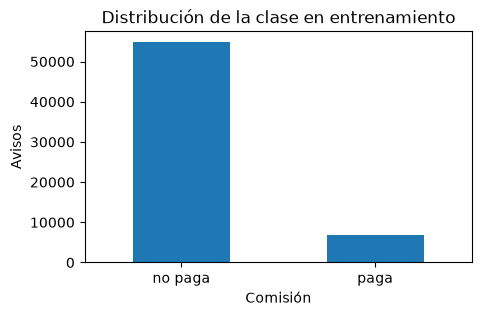

In [321]:
df_train['paga_comision'].value_counts().plot.bar(figsize=(5, 3))
plt.title('Distribución de la clase en entrenamiento')
plt.xlabel('Comisión')
plt.ylabel('Avisos')
plt.xticks(rotation=0)
plt.show()


## 3. Análisis de valores faltantes

Calculamos el porcentaje de valores nulos de cada columna para conocer que tan completa está la información disponible.

,tipo,únicos train,nulos train,% nulos train,% nulos predicción
ad_type,str,1,0,0.00,0.00
start_date,str,361,0,0.00,0.00
end_date,str,257,0,0.00,0.00
created_on,str,361,0,0.00,0.00
lat,float64,37869,9847,15.99,15.77
lon,float64,37685,10061,16.34,16.10
l1,str,3,0,0.00,0.00
l2,str,38,0,0.00,0.00
l3,str,560,3108,5.05,4.94
l4,str,679,38601,62.69,62.85


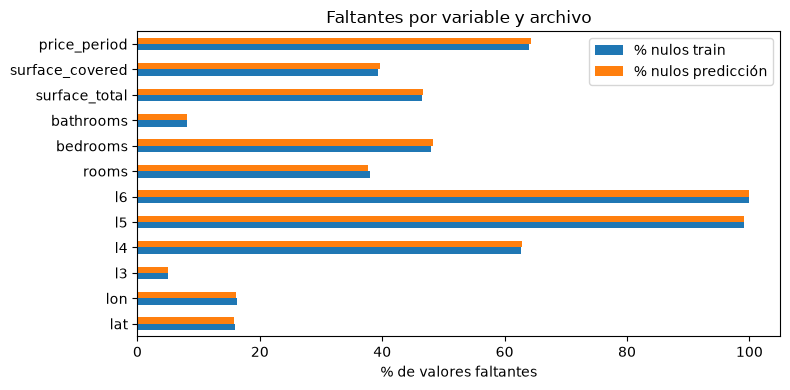

In [322]:
calidad = pd.DataFrame({
    'tipo': df_train.dtypes.astype(str),
    'únicos train': df_train.nunique(),
    'nulos train': df_train.isna().sum(),
    '% nulos train': df_train.isna().mean() * 100,
    '% nulos predicción': df_predict.isna().mean() * 100})

display(calidad.round(2))

calidad.loc[calidad['% nulos train'] > 0,
    ['% nulos train', '% nulos predicción']].plot.barh(figsize=(8, 4)) # grafico de barras horizontales, con 2 barras. Muestra las variables si el % de nulos en entrenamiento es mayor a 0
plt.xlabel('% de valores faltantes')
plt.title('Faltantes por variable y archivo')
plt.tight_layout()
plt.show()


### Observaciones sobre los faltantes

- `l6` está completamente vacía y `l5` tiene **99.16%** de faltantes.
- `l4` tiene **62.69%** y `price_period`, **63.91%**.
- `surface_total` y `surface_covered` presentan **46.49%** y **39.31%**, respectivamente.

La decisión de eliminar una variable no depende solo de su porcentaje de
nulos. Conservamos las superficies porque pueden estar relacionadas con el precio.
Más adelante vamos a imputar sus faltantes.


## 4. Exploración de las superficies

Analizaremos las variables de `surface_total` y `surface_covered` para conocer sus distribuciones e identificar posibles valores extremos o errores.

Se compararán la media y la mediana para evaluar que medida podría resultar más apropiada para imputar los valores faltantes.

In [323]:
display(df_train["surface_total"].describe().round(2))
display(df_train["surface_covered"].describe().round(2))

count     32952.00
mean        535.26
std        2841.37
min        -200.00
25%         164.00
50%         260.00
75%         460.00
max      200000.00
Name: surface_total, dtype: float64

count     37370.00
mean        229.05
std        1601.82
min        -170.00
25%         116.00
50%         170.00
75%         245.00
max      235000.00
Name: surface_covered, dtype: float64

In [324]:
df_train.loc[(df_train["surface_total"] < 0) | (df_train["surface_covered"] < 0)]

,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,l4,l5,l6,rooms,bedrooms,bathrooms,surface_total,surface_covered,price_period,title,paga_comision
id,,,,,,,,,,,,,,,,,,,,
wY/NFLCWKLeg0dxmP+y0Yw==,Propiedad,2019-07-16,9999-12-31,2019-07-16,-34.641356,-58.706481,Argentina,Bs.As. G.B.A. Zona Oeste,Ituzaingó,San Alberto,NaN,NaN,NaN,-2.0,NaN,-200.0,-170.0,Mensual,"Venta de casa, 3 ambientes, Ituzaingo Norte.",no paga
B7MX1s3EfXeVQK+drPd3YQ==,Propiedad,2019-10-28,2020-04-05,2019-10-28,-33.176233,-60.665941,Argentina,Santa Fe,Villa Amelia,NaN,NaN,NaN,2.0,2.0,NaN,-2.0,NaN,NaN,VENDO CASA VILLA AMELIA C/ PILETA Y PARQUE CON FRUTALES,no paga


### Revisión de superficies negativas

Encontramos **2 registros** con alguna superficie negativa. La trataremos como
un valor faltante, conservando el registro y el resto de sus características.



### Revisión de superficies máximas

Examinaremos las propiedades con mayores superficies, consultando ambas variables de superficie y el título del anuncio, para investigar si los valores extremos son correctos o podrían corresponder a errores de carga.

In [325]:
pd.set_option('display.max_colwidth', None) # para ver los titulos enteros
display(df_train.nlargest(10, "surface_total")[["surface_total", "surface_covered", "title"]])
display(df_train.nlargest(10, "surface_covered")[["surface_total", "surface_covered", "title"]])

,surface_total,surface_covered,title
id,,,
oInKbhuquyf166H8WpMzgQ==,200000.0,NaN,"Casa 200000m² en CHUBUT, Pilar, Villa Rosa, por U$S 4.700.000"
WzKWssHxvFGb51Lszu/lIw==,169000.0,100.0,CASA 3 AMB CON JARDIN AL FRENTE Y GARAJE
TMA30eFFBCPQTG5oNNoptg==,154000.0,113.0,Casa - Maschwitz Privado oportunidad
suexxqW0Rm0MgRt/ztlNCA==,146600.0,142600.0,VENTA CASA INTERNA 2/3 DORMITORIOS TIRO SUIZO
KZYEp/DmxQinDx8XGgFVIw==,142170.0,700.0,CASA DE CATEGORÍA 6dorm. VILLA RUMIPAL CALAMUCHITA
2KYwz2etcgK/Nrmgk2g7fA==,89555.0,430.0,"Casa 89555m² con 2 Plantas en WINEBERG, H. 3000, Vicente López, Olivos, por U$S 880.000"
0fIajsYMUO5REvFYyqXkWw==,87806.0,90.0,Venta Casa Maschwitz con Pileta y gran parque
WZwakYMLb+9B05ElEbLC2A==,80000.0,130.0,"Casa 80000m² con 2 Plantas en RUTA, Córdoba, La Falda, por U$S 275.000"
0Ve7shXYkWuAacrnOi6fXg==,75273.0,28688.0,Casa en Venta a la laguna BARRIO LA COMARCA


,surface_total,surface_covered,title
id,,,
grvgrGVF0S0U571cAqCjkw==,265.0,235000.0,Casa - Los Castaños
suexxqW0Rm0MgRt/ztlNCA==,146600.0,142600.0,VENTA CASA INTERNA 2/3 DORMITORIOS TIRO SUIZO
e/Gv/7tNeeFOesZlLbntrg==,3961.0,61354.0,Venta Casa Club de Campo Armenia
rrEfcEtDMIvJoQfmNg2VEA==,54750.0,54750.0,DUEO VENDE CASA
NuS7CeRjTcJbB5jUitBImQ==,50000.0,50000.0,Impecable Casa-Quinta en Venta
YavdTXylRx+fY6h4GrlaRA==,836.0,48391.0,CASA EN SAINT THOMAS ESTILO FRANCES
0Ve7shXYkWuAacrnOi6fXg==,75273.0,28688.0,Casa en Venta a la laguna BARRIO LA COMARCA
wQFWGXNvZ5aFbvwGojzwLQ==,75273.0,28688.0,Casa en Venta a la laguna BARRIO LA COMARCA
8GpXgs3HrnzIqceSDuAGng==,700.0,27376.0,"Casa en Venta, Neuquen Capital"


### Observaciones sobre superficies extremas

La tabla anterior permite comparar las superficies más altas con el título del
aviso. Un valor muy alto puede representar un terreno grande o un error de carga.
La información disponible no permite reconstruir con certeza todos los valores.
Por eso no eliminamos automáticamente los registros que superan el límite IQR.
Los árboles además no requieren escalar las variables numéricas.


### Cuantificación de superficies altas mediante IQR

Se utilizará el rango intercuartílico para identificar superficies superiores al límite Q3 + 1,5 × IQR y contar cuántos registros cumplen esa condición.

Este criterio se utilizará de forma exploratoria. Un valor señalado como atípico no se considerará automáticamente erróneo ni será eliminado.

In [326]:
Q1_sc = df_train['surface_covered'].quantile(0.25)
Q3_sc = df_train['surface_covered'].quantile(0.75)
IQR_sc = Q3_sc - Q1_sc
UB_sc = Q3_sc + 1.5 * IQR_sc
sc_limit = df_train['surface_covered'] > UB_sc
sc_limit_perc = sc_limit.sum() / df_train['surface_covered'].count() * 100

Q1_st = df_train['surface_total'].quantile(0.25)
Q3_st = df_train['surface_total'].quantile(0.75)
IQR_st = Q3_st - Q1_st
UB_st = Q3_st + 1.5 * IQR_st
st_limit = df_train['surface_total'] > UB_st
st_limit_perc = st_limit.sum() / df_train['surface_total'].count() * 100

print(f'Surface Covered: Upper Bound = {UB_sc}, {sc_limit.sum()} registros atípicos, % atípico = {round(sc_limit_perc, 2)}%')
print(f'Surface Total: Upper Bound = {UB_st}, {st_limit.sum()} registros atípicos, % atípico = {round(st_limit_perc, 2)}%')


Surface Covered: Upper Bound = 438.5, 1903 registros atípicos, % atípico = 5.09%
Surface Total: Upper Bound = 904.0, 3009 registros atípicos, % atípico = 9.13%


### Resultados del criterio IQR

- **Superficie cubierta:** límite de 438.5 m²; 1903 valores lo superan (**5.09%** de los disponibles).
- **Superficie total:** límite de 904 m²; 3009 valores lo superan (**9.13%** de los disponibles).

Los porcentajes se calculan sobre los valores no nulos. Ser estadísticamente
atípico no implica ser un error. Usamos este análisis para conocer los datos,
sin borrar todos los avisos con superficies altas.


### 4.1. Ambientes, dormitorios y baños

Revisamos negativos, ceros,
fracciones, distribución y valores máximos **en los dos archivos**.


In [327]:
conteos = ['rooms', 'bedrooms', 'bathrooms']

revision_train = pd.DataFrame()

revision_train['nulos'] = df_train[conteos].isna().sum()
revision_train['negativos'] = (df_train[conteos] < 0).sum()
revision_train['ceros'] = (df_train[conteos] == 0).sum()
revision_train['fraccionarios'] = (df_train[conteos] % 1 > 0).sum()
revision_train['mínimo'] = df_train[conteos].min()
revision_train['máximo'] = df_train[conteos].max()

display(revision_train)
display(df_train[conteos].describe().round(2))


,nulos,negativos,ceros,fraccionarios,mínimo,máximo
rooms,23443,0,0,0,1.0,30.0
bedrooms,29570,1,697,0,-2.0,37.0
bathrooms,5024,0,0,0,1.0,18.0


,rooms,bedrooms,bathrooms
count,38134.00,32007.00,56553.00
mean,4.25,3.02,2.29
std,1.75,1.28,1.21
min,1.00,-2.00,1.00
25%,3.00,2.00,1.00
50%,4.00,3.00,2.00
75%,5.00,4.00,3.00
max,30.00,37.00,18.00


In [328]:
revision_predict = pd.DataFrame()

revision_predict['nulos'] = df_predict[conteos].isna().sum()
revision_predict['negativos'] = (df_predict[conteos] < 0).sum()
revision_predict['ceros'] = (df_predict[conteos] == 0).sum()
revision_predict['fraccionarios'] = (df_predict[conteos] % 1 > 0).sum()
revision_predict['mínimo'] = df_predict[conteos].min()
revision_predict['máximo'] = df_predict[conteos].max()

display(revision_predict)
display(df_predict[conteos].describe().round(2))

,nulos,negativos,ceros,fraccionarios,mínimo,máximo
rooms,15496,0,0,0,1.0,30.0
bedrooms,19824,0,459,0,0.0,335.0
bathrooms,3324,0,0,0,1.0,16.0


,rooms,bedrooms,bathrooms
count,25558.00,21230.00,37730.00
mean,4.26,3.05,2.29
std,1.69,2.59,1.19
min,1.00,0.00,1.00
25%,3.00,2.00,1.00
50%,4.00,3.00,2.00
75%,5.00,4.00,3.00
max,30.00,335.00,16.00


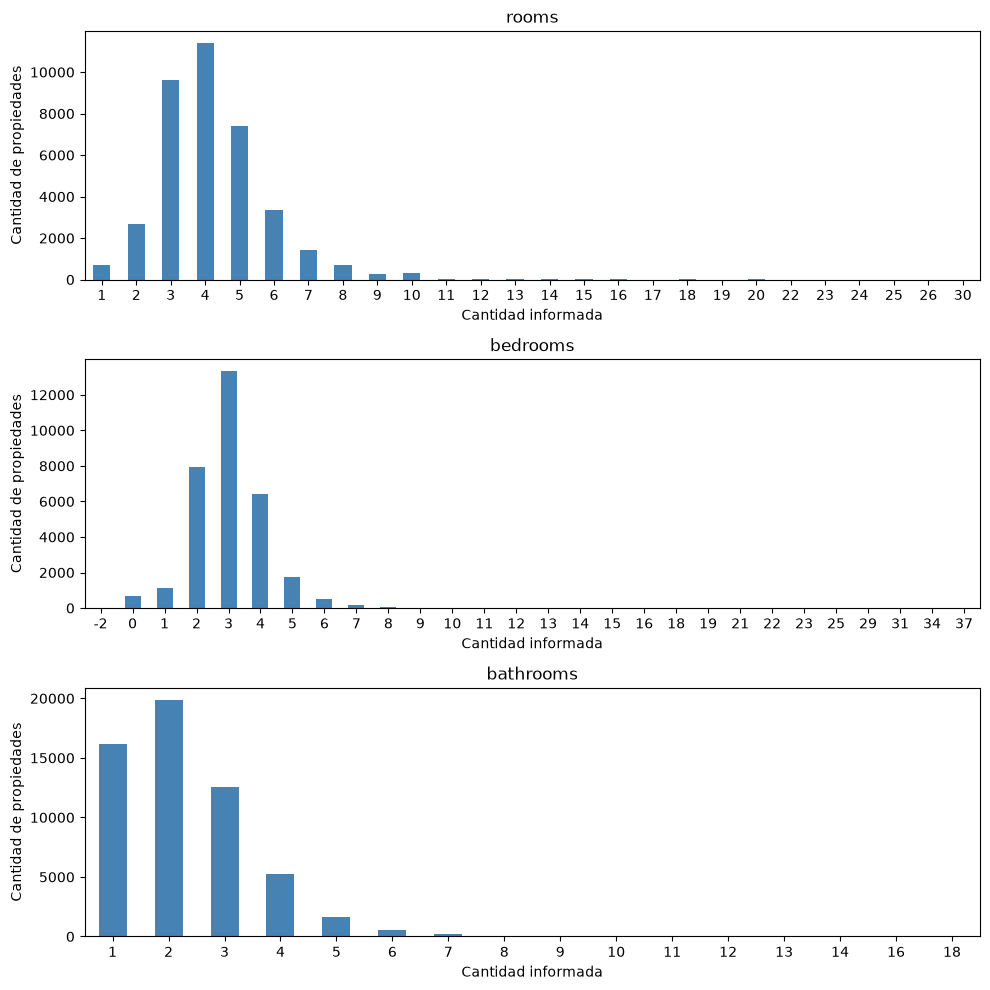

In [329]:
fig, ejes = plt.subplots(3, 1, figsize=(10, 10))

for col, eje in zip(conteos, ejes):
    frecuencias = df_train[col].value_counts().sort_index()
    frecuencias.index = frecuencias.index.astype(int)

    frecuencias.plot.bar(ax=eje, rot=0, color='steelblue')

    eje.set_title(col)
    eje.set_xlabel('Cantidad informada')
    eje.set_ylabel('Cantidad de propiedades')

plt.tight_layout()
plt.show()


In [330]:
pd.set_option('display.max_colwidth', None)

display(df_train.loc[(df_train[conteos] < 0).any(axis=1), conteos + ['title']]) # ver los que tienen algun valor negativo

print("5 con mas baños")
display(df_train.nlargest(5, 'bathrooms')[conteos + ['title']])

print("5 con mas piezas")
display(df_train.nlargest(5, 'bedrooms')[conteos + ['title']])

print("5 con mas piezas (predict)")
display(df_predict.nlargest(5, 'bedrooms')[conteos + ['title']])


,rooms,bedrooms,bathrooms,title
id,,,,
wY/NFLCWKLeg0dxmP+y0Yw==,NaN,-2.0,NaN,"Venta de casa, 3 ambientes, Ituzaingo Norte."


5 con mas baños


,rooms,bedrooms,bathrooms,title
id,,,,
khBGKJ+cEkpYSqhA5ufT+g==,NaN,16.0,18.0,ESTADOS UNIDOS 800
bP0ZKapukwrs5TD6HGMlOw==,18.0,16.0,16.0,Casa - Federacion
1roOsOHI7Y1f1hRqE0X+0g==,22.0,22.0,16.0,MINA CLAVERO!! VENTA de INMUEBLE y FONDO DE COMERCIO - HOSTERIA!!
gU/Fqrc1LSxbdJCaGtrmDA==,10.0,10.0,14.0,Complejo de cabañas en Villa Cd Parque Los Reartes
3fFmWbVzRTNTiV7baP6t9A==,20.0,13.0,13.0,VENTA CASA 613M2 IDEAL USO COMERCIAL


5 con mas piezas


,rooms,bedrooms,bathrooms,title
id,,,,
DvWPGpboszxiLozwdH3sog==,NaN,37.0,7.0,"CASA EN VENTA, SAN TELMO, EN BLOCK A RECICLAR"
TvvPCY9n/7ZHhvy7w7BkLw==,5.0,34.0,3.0,CASA VENTA MIRAFLORES OPORTUNIDAD
upA0T+49NMUJp6NGw/hv2g==,NaN,34.0,3.0,Susana Aravena Propiedades-FV-Excelente casa en venta en El Canton
XqSMxhv2NRzAYetGXqk84w==,6.0,31.0,1.0,SE VENDE HERMOSA CASA EN BARRIO SAN DANIEL!
U9SC335yXXjxq2E674ieYA==,30.0,29.0,NaN,Balvanera: edificio en venta para reciclar


5 con mas piezas (predict)


,rooms,bedrooms,bathrooms,title
id,,,,
HYHwOQXRz52nKjNcAuvs7Q==,3.0,335.0,2.0,Casa para 2 Familias en Venta en Berazategui Oeste
aOyGIr/OtgugRbLa3GrB6Q==,NaN,44.0,NaN,"Casa 825m² con Dependencias en QUINTANA, Pres. 900, San Isidro, Acassuso, por U$S 1.700.000"
Y1W5m7tcWpjWwahhlEVujw==,6.0,33.0,1.0,Casa - Piñeyro
QPUdXHEdATQ0+dQPKaHJCg==,NaN,25.0,10.0,Sanchez de Loria 500 Balvanera/Almagro Casa 18amb U$750.000 Geriatrico/Apto Prof
NEXw87kN9moCz/QfpsRQ7w==,4.0,21.0,1.0,Casa en venta a reciclar con gran terreno


**Qué encontramos y qué hacemos:**

- No hay baños negativos ni en cero. En entrenamiento van de 1 a 18;
  los valores más frecuentes son 1, 2 y 3. El registro con 18 baños requiere revisión,
  pero también hay hosterías y complejos: muchos baños no bastan para declarar un error.
- Hay un dormitorio con valor **−2**, que pasará a faltante. Hay 697 avisos con
  cero dormitorios en entrenamiento y 459 en predicción. Cero puede representar
  una vivienda sin dormitorio separado: lo conservamos.
- Los máximos de dormitorios merecen atención:
  en predicción hay **335 dormitorios con 3 ambientes**, una inconsistencia clara.
- Faltan ambientes en 38,07% y dormitorios en 48,02% de entrenamiento, frente a
  8,16% en baños.


### 4.2. Coherencia entre variables y ceros en superficies

No alcanza con mirar cada columna por separado. Buscamos dormitorios mayores
que ambientes, superficie cubierta mayor que total y superficies no positivas.
El título ayuda a investigar, aunque no siempre permite reconstruir el dato.


In [331]:
print('Dormitorios mayores que ambientes:',
      (df_train['bedrooms'] > df_train['rooms']).sum())

print('Superficie cubierta mayor que total:',
      (df_train['surface_covered'] > df_train['surface_total']).sum())

print('Superficie total en cero o negativa:',
      (df_train['surface_total'] <= 0).sum())

print('Superficie cubierta en cero o negativa:',
      (df_train['surface_covered'] <= 0).sum())


Dormitorios mayores que ambientes: 134
Superficie cubierta mayor que total: 1124
Superficie total en cero o negativa: 44
Superficie cubierta en cero o negativa: 1


In [332]:
print('Dormitorios mayores que ambientes:',
      (df_predict['bedrooms'] > df_predict['rooms']).sum())

print('Superficie cubierta mayor que total:',
      (df_predict['surface_covered'] > df_predict['surface_total']).sum())

print('Superficie total en cero o negativa:',
      (df_predict['surface_total'] <= 0).sum())

print('Superficie cubierta en cero o negativa:',
      (df_predict['surface_covered'] <= 0).sum())

Dormitorios mayores que ambientes: 84
Superficie cubierta mayor que total: 689
Superficie total en cero o negativa: 28
Superficie cubierta en cero o negativa: 0


In [333]:
dormitorios_mayores = df_train['bedrooms'] > df_train['rooms']

display(df_train.loc[dormitorios_mayores,
    ['rooms', 'bedrooms', 'title']].head(5))


cubierta_mayor = df_train['surface_covered'] > df_train['surface_total']

display(df_train.loc[cubierta_mayor,
    ['surface_total', 'surface_covered', 'title']].head(5))

,rooms,bedrooms,title
id,,,
iupjaKpRGlTPSY5T1gnufQ==,1.0,3.0,"Vendo Casa, B San Pedro, San Martn, Mendoza"
kjhCqh4lAhFgC5zNvfjKcw==,1.0,2.0,Casa en venta de 2 dormitorios c/ cochera en Rafaela
tkuuFHvm9siCOu6d2YNp+A==,4.0,5.0,Casa en venta en Quilmes Oeste
TvvPCY9n/7ZHhvy7w7BkLw==,5.0,34.0,CASA VENTA MIRAFLORES OPORTUNIDAD
c7N5lN0Fic7H9D1s5DZkBg==,2.0,3.0,VENDO CASA CANDELARIA (Ref.#424359) JPR


,surface_total,surface_covered,title
id,,,
DHGxNthMAqpXdQ8EGZ4h5w==,156.0,165.0,CASA EN VENTA 4 AMBIENTES CON GARAGE EN HAEDO
i3q9VNySYLZy4q6p6tU4fQ==,150.0,1050.0,"Chalet Epoca, Detalles de Estilo Totalmente Amoblado"
+1sN0xbgrMPNn4WFb0ErVw==,160.0,176.0,CASA 4 DORMIT. DE 2 PLANTAS BARRIO GENERAL PAZ
jIkxly/kq1dCKGgN+LI8HQ==,100.0,432.0,CASA EN VENTA CIRC 2 SECC 2
+shU70z0+pPleKjiIQ/qTg==,65.0,67.0,"Departamento en Venta en Parque Centenario, 2 ambientes en dúplex con baño y toilette, 65 m2 + balcón, - Río de Janeiro 700"


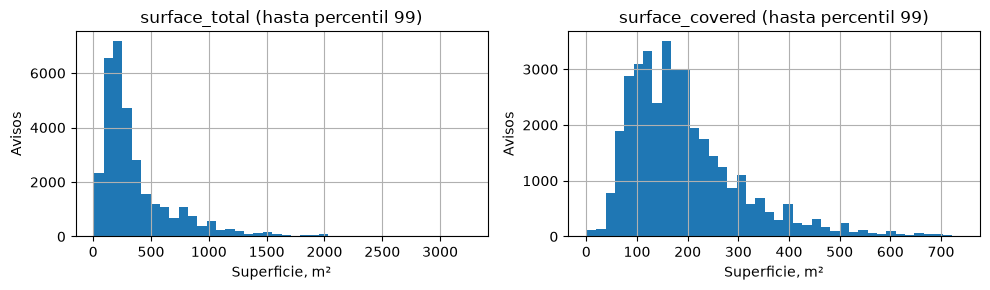

In [334]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3))
for col, eje in zip(['surface_total', 'surface_covered'], ejes):
    valores = df_train.loc[df_train[col] > 0, col]
    valores.loc[valores <= valores.quantile(0.99)].hist(bins=40, ax=eje)
    eje.set_title(col + ' (hasta percentil 99)')
    eje.set_xlabel('Superficie, m²')
    eje.set_ylabel('Avisos')
plt.tight_layout()
plt.show()


En entrenamiento hay **134** casos con dormitorios mayores que ambientes y en
predicción, **84**. Adoptamos una regla sencilla: cuando están informados ambos
valores y dormitorios supera ambientes, pasamos **dormitorios a faltante**.
Es una decisión conservadora frente a una inconsistencia; no conocemos el valor real.

Hay **42 superficies totales en cero** en entrenamiento y 28 en predicción.
Una vivienda no puede tener superficie total cero: se tratan como faltantes,
igual que las superficies negativas. Se conserva el resto del aviso.

La cubierta supera a la total en **1.124** avisos de entrenamiento y 689 de
predicción. Es una señal para revisar: podría haber errores o distintas formas
de informar terreno y metros construidos en varias plantas. El diccionario no
permite resolver todos los casos. Conservamos ambos valores positivos, sin
intercambiarlos ni borrar esos avisos. Los extremos tampoco se eliminan por IQR.


### 4.3. Latitud y longitud

Las coordenadas negativas son normales en Argentina y Uruguay. Primero
comprobamos los rangos geográficos generales; después las comparamos con el país.
Una coordenada puede estar dentro de −90/90 y aun así no corresponder al país informado.


In [335]:
lat_invalida = (df_train['lat'] < -90) | (df_train['lat'] > 90)
lon_invalida = (df_train['lon'] < -180) | (df_train['lon'] > 180)

argentina_norte = (df_train['l1'] == 'Argentina') & (df_train['lat'] > 0)

coordenadas_incompletas = df_train['lat'].isna() | df_train['lon'].isna()

print('Coordenadas fuera del rango:', (lat_invalida | lon_invalida).sum())
print('Argentina con latitud positiva:', argentina_norte.sum())
print('Avisos con alguna coordenada faltante:', coordenadas_incompletas.sum())

# Ver los avisos de Argentina con latitud positiva
display(df_train.loc[argentina_norte,
    ['l1', 'l2', 'l3', 'lat', 'lon', 'title']])

Coordenadas fuera del rango: 0
Argentina con latitud positiva: 2
Avisos con alguna coordenada faltante: 10061


,l1,l2,l3,lat,lon,title
id,,,,,,
jyS7YpJ/owPhRVdB6a3Rmw==,Argentina,Bs.As. G.B.A. Zona Sur,Quilmes,85.051129,-180.000000,"Casa en Venta en Quilmes oeste , Quilmes U$S 180000"
8bHpVgaiAZJslk6JTww5PQ==,Argentina,Bs.As. G.B.A. Zona Sur,Lanús,37.412933,-4.496101,"Casa en Venta ubicado en Lanús Oeste, Zona Sur"


In [336]:
lat_invalida = (df_predict['lat'] < -90) | (df_predict['lat'] > 90)
lon_invalida = (df_predict['lon'] < -180) | (df_predict['lon'] > 180)

argentina_norte = (df_predict['l1'] == 'Argentina') & (df_predict['lat'] > 0)

coordenadas_incompletas = df_predict['lat'].isna() | df_predict['lon'].isna()

print('Coordenadas fuera del rango:', (lat_invalida | lon_invalida).sum())
print('Argentina con latitud positiva:', argentina_norte.sum())
print('Avisos con alguna coordenada faltante:', coordenadas_incompletas.sum())

display(df_predict.loc[argentina_norte,
    ['l1', 'l2', 'l3', 'lat', 'lon', 'title']])

Coordenadas fuera del rango: 0
Argentina con latitud positiva: 0
Avisos con alguna coordenada faltante: 6610


,l1,l2,l3,lat,lon,title
id,,,,,,


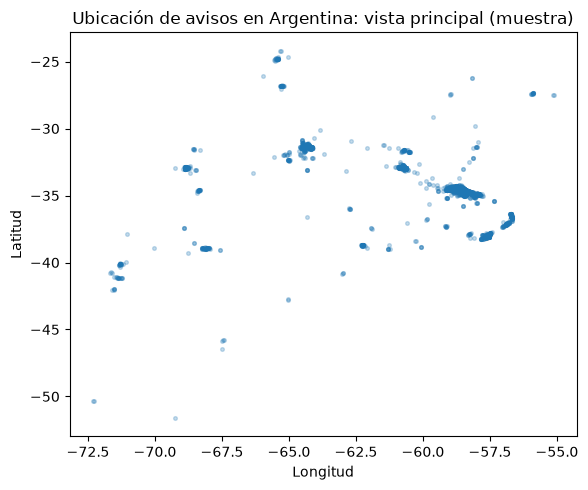

In [337]:
ubicaciones = df_train.loc[(df_train['l1'] == 'Argentina') &
    df_train['lat'].between(-60, -20) & df_train['lon'].between(-80, -50)]
muestra_geo = ubicaciones.sample(n=min(5000, len(ubicaciones)), random_state=42)
plt.figure(figsize=(6, 5))
plt.scatter(muestra_geo['lon'], muestra_geo['lat'], s=7, alpha=0.25)
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.title('Ubicación de avisos en Argentina: vista principal (muestra)')
plt.tight_layout()
plt.show()


No hay coordenadas fuera de los límites mundiales, pero **dos avisos de Argentina
tienen latitud positiva**: uno de Quilmes aparece en 85,05/−180 y otro de Lanús
en 37,41/−4,50. El país y el título contradicen la ubicación. Pasamos **latitud y
longitud de esos avisos a faltante**, porque no sabemos reconstruir su posición.

El resto se conserva, incluyendo coordenadas positivas de Estados Unidos.
Se ve una concentración de avisos en la zona de Buenos Aires; la muestra no está
distribuida de manera uniforme por el territorio. Los faltantes se imputarán
solo con datos de entrenamiento y conservarán una marca de ausencia.


### 4.4. País, región, ciudad, barrio y sub-barrio

Según el diccionario, `l1` es país, `l2` región/zona/provincia, `l3` ciudad,
`l4` barrio, `l5` sub-barrio y `l6` catastro. Revisamos cantidad de categorías,
concentración, faltantes y categorías de predicción que no aparecen en entrenamiento.


In [338]:
lugares = ['l1', 'l2', 'l3', 'l4', 'l5', 'l6']

revision_train = pd.DataFrame()

revision_train['categorías distintas'] = df_train[lugares].nunique()
revision_train['nulos'] = df_train[lugares].isna().sum()
revision_train['% nulos'] = df_train[lugares].isna().mean() * 100

display(revision_train.round(2))

,categorías distintas,nulos,% nulos
l1,3,0,0.00
l2,38,0,0.00
l3,560,3108,5.05
l4,679,38601,62.69
l5,17,61057,99.16
l6,0,61577,100.00


In [339]:
revision_predict = pd.DataFrame()

revision_predict['categorías distintas'] = df_predict[lugares].nunique()
revision_predict['nulos'] = df_predict[lugares].isna().sum()
revision_predict['% nulos'] = df_predict[lugares].isna().mean() * 100

display(revision_predict.round(2))

,categorías distintas,nulos,% nulos
l1,3,0,0.00
l2,38,0,0.00
l3,512,2028,4.94
l4,622,25804,62.85
l5,18,40717,99.18
l6,0,41054,100.00


In [340]:
display(df_train['ad_type'].value_counts(dropna=False))
display(df_train['price_period'].value_counts(dropna=False))

ad_type
Propiedad    61577
Name: count, dtype: int64

price_period
NaN        39356
Mensual    22221
Name: count, dtype: int64

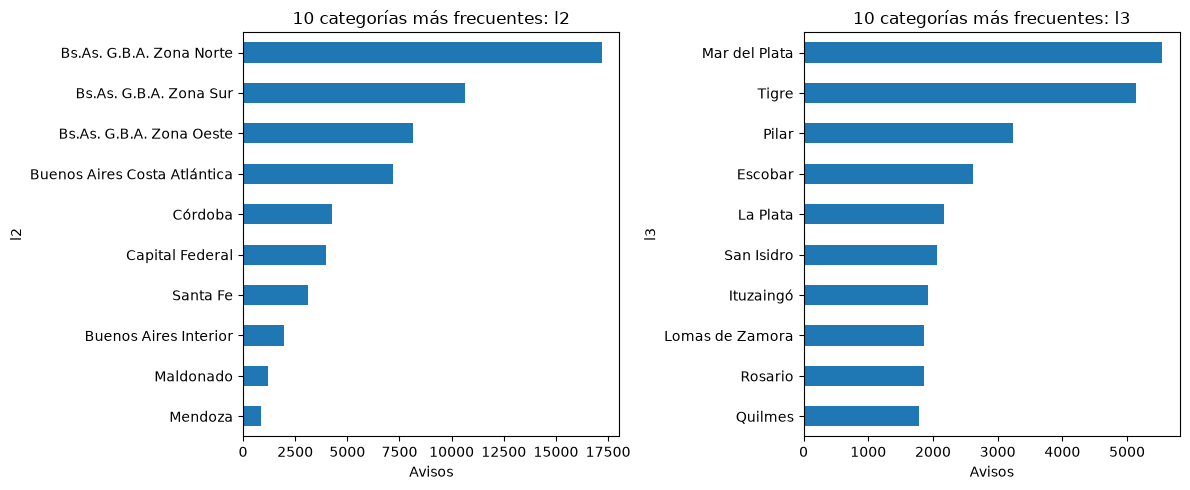

,cantidad
l1,
Argentina,59660
Uruguay,1780
Estados Unidos,137


,cantidad
l5,
Barrio El Golf,77
Barrio Los Alisos,72
Barrio Los Lagos,69
Barrio Los Tilos,55
Barrio Barrancas del Lago,38


In [341]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
for col, eje in zip(['l2', 'l3'], ejes):
    df_train[col].value_counts().head(10).sort_values().plot.barh(ax=eje)
    eje.set_title('10 categorías más frecuentes: ' + col)
    eje.set_xlabel('Avisos')
plt.tight_layout()
plt.show()
display(df_train['l1'].value_counts().rename('cantidad').to_frame())
display(df_train['l5'].value_counts().head(5).rename('cantidad').to_frame())


Argentina reúne **59.660 de los 61.577 avisos**; también hay de Uruguay y Estados
Unidos. Por eso no aplicamos reglas geográficas de Argentina a todo el dataset.
`l2` tiene 38 categorías, mientras que ciudad y barrio tienen 560 y 679.
En predicción aparecen **63 ciudades y 58 barrios nuevos**, aunque corresponden
a pocos avisos (73 y 75, respectivamente).

Para mantener sencillo el modelo, codificamos país y región con `get_dummies`.
Ciudad y barrio podrían aportar información, pero incluirlos aumenta las columnas
y exige atender categorías poco frecuentes.
Sub-barrio tiene 99,16% de nulos y catastro está vacío, por lo que no se usan.
`ad_type` es constante. `price_period` solo informa “Mensual” o falta; conservamos
la marca de presencia, sin interpretar ese texto como una prueba de alquiler.


### 4.5. Fechas del aviso

`created_on` es el alta de la primera versión, `start_date` el alta del aviso
y `end_date` su baja. Revisamos conversión, orden temporal y datos redundantes.



In [342]:
display(df_train['end_date'].value_counts(dropna=False).head(10))
display(df_predict['end_date'].value_counts(dropna=False).head(10))

end_date
9999-12-31    28771
2020-04-28     2144
2019-12-23     2098
2020-04-27     2050
2020-02-19     1535
2020-02-13     1320
2020-04-01      760
2020-04-08      602
2020-01-21      514
2020-02-18      498
Name: count, dtype: int64

end_date
9999-12-31    19108
2020-04-27     1482
2020-04-28     1427
2019-12-23     1298
2020-02-19     1024
2020-02-13      886
2020-04-01      497
2020-04-08      400
2020-02-18      357
2020-01-21      309
Name: count, dtype: int64

In [343]:
creada_train = pd.to_datetime(df_train['created_on'], errors='coerce')
inicio_train = pd.to_datetime(df_train['start_date'], errors='coerce')

baja_texto_train = df_train['end_date'].replace('9999-12-31', None)
baja_train = pd.to_datetime(baja_texto_train, errors='coerce')

bajas_invalidas_train = baja_texto_train.notna() & baja_train.isna()

print('Primera alta:', creada_train.min())
print('Última alta:', creada_train.max())

print('Creación faltante o inválida:', creada_train.isna().sum())
print('Inicio faltante o inválido:', inicio_train.isna().sum())
print('Bajas no interpretables:', bajas_invalidas_train.sum())

print('Creación e inicio coinciden (%):',
      (creada_train == inicio_train).mean() * 100)

print('Bajas con 9999-12-31:',
      (df_train['end_date'] == '9999-12-31').sum())

print('Baja anterior al alta:', (baja_train < inicio_train).sum())

Primera alta: 2019-03-21 00:00:00
Última alta: 2020-04-13 00:00:00
Creación faltante o inválida: 0
Inicio faltante o inválido: 0
Bajas no interpretables: 0
Creación e inicio coinciden (%): 100.0
Bajas con 9999-12-31: 28771
Baja anterior al alta: 0


In [344]:
creada_predict = pd.to_datetime(df_predict['created_on'], errors='coerce')
inicio_predict = pd.to_datetime(df_predict['start_date'], errors='coerce')

baja_texto_predict = df_predict['end_date'].replace('9999-12-31', None)
baja_predict = pd.to_datetime(baja_texto_predict, errors='coerce')

bajas_invalidas_predict = baja_texto_predict.notna() & baja_predict.isna()

print('Primera alta:', creada_predict.min())
print('Última alta:', creada_predict.max())

print('Creación faltante o inválida:', creada_predict.isna().sum())
print('Inicio faltante o inválido:', inicio_predict.isna().sum())
print('Bajas no interpretables:', bajas_invalidas_predict.sum())

print('Creación e inicio coinciden (%):',
      (creada_predict == inicio_predict).mean() * 100)

print('Bajas con 9999-12-31:',
      (df_predict['end_date'] == '9999-12-31').sum())

print('Baja anterior al alta:', (baja_predict < inicio_predict).sum())

Primera alta: 2019-03-21 00:00:00
Última alta: 2020-04-13 00:00:00
Creación faltante o inválida: 0
Inicio faltante o inválido: 0
Bajas no interpretables: 0
Creación e inicio coinciden (%): 100.0
Bajas con 9999-12-31: 19108
Baja anterior al alta: 0


En ambos archivos las altas van de **21/03/2019 a 13/04/2020** y `created_on`
coincide con `start_date` en el 100% de las filas: usar ambas repetiría información.
Hay **28.771** bajas con `9999-12-31` en entrenamiento y **19.108** en predicción.
No se detectan bajas conocidas anteriores al alta.

Usamos año y mes de `created_on`, disponibles al publicar el aviso. Dejamos afuera
`start_date` por redundancia y `end_date` porque describe información posterior
al alta y muchas bajas son desconocidas.

### 4.6. Título del aviso

Es texto libre, no una categoría con pocas opciones. Revisamos longitud,
títulos vacíos, repeticiones y algunas palabras comprensibles. Después exploramos precios, superficies y tipos de inmueble mencionados
en el título para crear variables adicionales.

In [345]:
titulos_train = df_train['title'].fillna('')

display(titulos_train.head(5))
display(titulos_train.str.len().describe())

print('Títulos vacíos:',
      (titulos_train.str.strip() == '').sum())

print('Títulos repetidos:',
      titulos_train.duplicated().sum())

id
vz/dYJl3t6dAAhuCMR9pFg==     Casa en Venta en Primera sección, Tigre U$S 190000
7WuevfRjW78WomnkinRSAA==    Casa en venta en Tigre con dos dormitorios y jardin
zZlOOuCPY//CPsAuwgfICA==           Casa de 3 ambientes en Venta en Villa crespo
dZmdfoiNyUCOgDbRXIuPCg==          DUPLEX A ESTRENAR/ 2 DORMITORIOS / Jose C Paz
nt8/Rc6J4m3all/FkfX0gQ==               Inmueble en block en Venta. 8 Amb. 6 Dor
Name: title, dtype: str

count    61577.000000
mean        43.019066
std         19.301511
min          1.000000
25%         29.000000
50%         42.000000
75%         54.000000
max        197.000000
Name: title, dtype: float64

Títulos vacíos: 0
Títulos repetidos: 21371


In [346]:
titulos_predict = df_predict['title'].fillna('')

display(titulos_predict.head(5))
display(titulos_predict.str.len().describe())

print('Títulos vacíos:',
      (titulos_predict.str.strip() == '').sum())

print('Títulos repetidos:',
      titulos_predict.duplicated().sum())

id
YNsMDAiJDbpSUbOHt+rSvQ==                            Triplex en Venta en Ciudad Jardin
BoKiYfTPcZ8LpdTSuS7PVA==                                           Casa - Grand Bourg
sUU+KBSqGEYMNmENHFLomA==       Casa en Venta en Banfield oeste,  banfield  U$S 350000
4aFQ09OzllVbPl57kB7oCQ==    Casa 4 ambientes Reciclada a nueva en Impecable estado!!!
bczZnJ0pADQI2XNR4ivWvg==            Chalet en Venta. 3 Amb. 2 Dor. 150 M2. 100 M2 Cub
Name: title, dtype: str

count    41054.000000
mean        42.923564
std         19.267726
min          3.000000
25%         29.000000
50%         42.000000
75%         54.000000
max        234.000000
Name: title, dtype: float64

Títulos vacíos: 0
Títulos repetidos: 12942


In [347]:
titulos_train = df_train['title'].fillna('').str.lower()

palabras_train = pd.DataFrame()

palabras_train['pileta'] = titulos_train.str.contains('pileta|piscina')
palabras_train['country'] = titulos_train.str.contains('country|barrio cerrado')
palabras_train['suite'] = titulos_train.str.contains('suite')
palabras_train['cochera'] = titulos_train.str.contains('cochera|garage|garaje')
palabras_train['estrenar'] = titulos_train.str.contains('estrenar')
palabras_train['duplex'] = titulos_train.str.contains('dúplex|duplex|tríplex|triplex')

titulos_predict = df_predict['title'].fillna('').str.lower()

palabras_predict = pd.DataFrame()

palabras_predict['pileta'] = titulos_predict.str.contains('pileta|piscina')
palabras_predict['country'] = titulos_predict.str.contains('country|barrio cerrado')
palabras_predict['suite'] = titulos_predict.str.contains('suite')
palabras_predict['cochera'] = titulos_predict.str.contains('cochera|garage|garaje')
palabras_predict['estrenar'] = titulos_predict.str.contains('estrenar')
palabras_predict['duplex'] = titulos_predict.str.contains('dúplex|duplex|tríplex|triplex')

frecuencias_palabras = pd.DataFrame()

frecuencias_palabras['entrenamiento'] = palabras_train.mean() * 100
frecuencias_palabras['predicción'] = palabras_predict.mean() * 100

display(frecuencias_palabras.round(2))


,entrenamiento,predicción
pileta,3.68,3.74
country,1.72,1.69
suite,0.15,0.21
cochera,5.11,5.18
estrenar,3.10,3.16
duplex,3.83,3.62


No hay títulos vacíos. La mediana de longitud es **42 caracteres** en ambos archivos;
hay muchos títulos genéricos repetidos. Un título repetido no prueba que sea la
misma propiedad: no se usa solo ese campo para eliminar duplicados.

Creamos seis marcas sencillas de presencia de palabras. Son coincidencias de texto,
no una lectura completa del anuncio: por ejemplo, “sin pileta” también coincide.
Se evalúa su utilidad con el resto de las variables, sin modelos de lenguaje ni
una codificación de cada título como categoría.


### 4.6.1. Información que podemos recuperar del título

Además de las seis palabras anteriores, los títulos pueden mencionar precios,
superficies y tipos de inmueble. Por ejemplo, encontramos anuncios con
`U$S 550000`, “lote 370mts2” y “Hotel boutique”. Primero miramos los casos reales
y después extraemos información mediante **regex** (patrones de texto).

Los datos originales se conservan. Las cifras extraídas irán en columnas nuevas:
`precio_titulo_usd` y `m2_titulo`.
También conservamos una marca de faltante para cada una.

Para reconocer las variantes observadas, primero pasamos `u$s`, `u$d` y `us$` a
“usd”, y las unidades “m²”, “mts2” y “mts²” a “m2”, solo en un texto auxiliar.


In [348]:
texto_train = titulos_train.str.replace(r'u\$s|u\$d|us\$', 'usd', regex=True)
texto_train = texto_train.str.replace('m²', 'm2', regex=False)
texto_train = texto_train.str.replace('mts2', 'm2', regex=False)
texto_train = texto_train.str.replace('mts²', 'm2', regex=False)

texto_predict = titulos_predict.str.replace(r'u\$s|u\$d|us\$', 'usd', regex=True)
texto_predict = texto_predict.str.replace('m²', 'm2', regex=False)
texto_predict = texto_predict.str.replace('mts2', 'm2', regex=False)
texto_predict = texto_predict.str.replace('mts²', 'm2', regex=False)

formato_entero = r'[0-9]+|[0-9]{1,3}(\.[0-9]{3})+'
patron_precio = r'usd\s*([0-9.,]+)'
patron_m2 = r'([0-9.,]+)\s*m2\b'

In [349]:
con_dolares_train = texto_train.str.contains('usd', regex=False)
con_dolares_predict = texto_predict.str.contains('usd', regex=False)

print('Ejemplos de entrenamiento con dólares en el título:')
display(df_train.loc[con_dolares_train, ['title']].head(8))

print('Ejemplos de predicción:')
display(df_predict.loc[con_dolares_predict, ['title']].head(5))

Ejemplos de entrenamiento con dólares en el título:


,title
id,
vz/dYJl3t6dAAhuCMR9pFg==,"Casa en Venta en Primera sección, Tigre U$S 190000"
G0ynZtcc/TRw7d2ODm3W2w==,"Casa en Venta en Temperley, lomas de zamora U$S 80000"
ZBoNCxg5LuGY5EGSn2BiQg==,"Casa en Venta en El lucero, Los polvorines U$S 85000"
dCWo91tsTbUH7v5f3n3VBg==,Ruta 4 Km 4 100 - U$D 220.000 - Casa en Venta
gs6fM2DBJJeQ3UdE0XVmBA==,"Casa en Venta en Carilo, pinamar U$S 550000"
YkN0fijfAPuvyP5g90Ue2w==,48 E/ 27 Y 100 - U$D 180.000 - Casa en Venta
GPWJ96Jkd8Mlcejh4dYeIQ==,Moreno 3900 - U$D 95.000 - Tipo casa PH en Venta
GYb+IBLtLdFSRMJwqNl3lQ==,"Casa en Venta en Lomas de zamora oeste, lomas de zamora U$S 180000"


Ejemplos de predicción:


,title
id,
sUU+KBSqGEYMNmENHFLomA==,"Casa en Venta en Banfield oeste, banfield U$S 350000"
0D2Aj3O4F2qhYWQ2Cinm8A==,Tte Cnel J P Giribone 3100 PB - U$D 189.000 - Tipo casa PH en Venta
lhXkg2in7fvNqT4kYwu7eQ==,"Casa 450m² con Cochera en ACASSUSO 2200, San Isidro, Beccar, por U$S 650.000"
0s0ulTAuZg+tKsz8VpyQbQ==,Oportunidad Se Vende Casa En Solares Del Sur 100 - U$D 105.000 - Casa
rGeUOykJC6l5eLEt+0lvWA==,"Casa 488m² con 2 Plantas en RIVERA INDARTE 900, San Isidro, Acassuso, por U$S 650.000"


### 4.6.2. Precio en dólares escrito en el título

`str.extract` recupera el fragmento que coincide con un patrón. En
`usd\s*([0-9.,]+)`:

- `usd` busca la moneda ya normalizada.
- `\s*` permite que haya espacios o que el importe esté pegado a la moneda.
- `[0-9.,]+` busca una secuencia de dígitos, puntos o comas.
- Los paréntesis indican qué parte queremos recuperar: el número.

Antes de convertirlo, comprobamos el formato. `formato_entero` admite números
como “350000” o “350.000”: dígitos solos o grupos de miles separados por puntos.
`[0-9]{1,3}` significa de uno a tres dígitos y `\.[0-9]{3}` significa un punto
seguido por tres dígitos. `fullmatch` exige que coincida el número completo.
En esta primera versión dejamos sin convertir formatos decimales o con comas.

Si el título menciona alquiler o temporada sin mencionar venta, dejamos el
precio como faltante. Si dice **venta y alquiler**, conservamos el precio cuando
supera USD 1.000 y cumple los demás controles. El patrón `\bventa\b` busca la
palabra completa “venta”; así “ventanales” no se interpreta como una venta.

También dejamos como faltantes los anticipos, cuotas, millones abreviados,
precios por m² y títulos que mencionan dólares más de una vez. Descartamos los
importes de USD 1.000 o menos: en los ejemplos revisados aparecen importes por m²
o números de dormitorios después de la moneda. Es una regla conservadora de
esta extracción.

In [350]:
precio_texto_train = texto_train.str.extract(patron_precio, expand=False).str.strip('.,')
formato_valido_train = precio_texto_train.str.fullmatch(formato_entero, na=False)
precio_texto_train.loc[formato_valido_train == False] = None

precio_train = pd.to_numeric(precio_texto_train.str.replace('.', '', regex=False), errors='coerce')
precio_train.loc[precio_train <= 1000] = np.nan

menciona_venta_train = texto_train.str.contains(r'\bventa\b')
menciona_alquiler_train = texto_train.str.contains('alquiler|temporada')
solo_alquiler_train = menciona_alquiler_train & (menciona_venta_train == False)
precio_train.loc[solo_alquiler_train] = np.nan

precio_ambiguo_train = texto_train.str.contains('anticipo|cuota|millon|millón|por m2|x m2|/m2')
precio_train.loc[precio_ambiguo_train] = np.nan
precio_train.loc[texto_train.str.count('usd') > 1] = np.nan

In [351]:
precio_texto_predict = texto_predict.str.extract(patron_precio, expand=False).str.strip('.,')
formato_valido_predict = precio_texto_predict.str.fullmatch(formato_entero, na=False)
precio_texto_predict.loc[formato_valido_predict == False] = None

precio_predict = pd.to_numeric(precio_texto_predict.str.replace('.', '', regex=False), errors='coerce')
precio_predict.loc[precio_predict <= 1000] = np.nan

menciona_venta_predict = texto_predict.str.contains(r'\bventa\b')
menciona_alquiler_predict = texto_predict.str.contains('alquiler|temporada')
solo_alquiler_predict = menciona_alquiler_predict & (menciona_venta_predict == False)
precio_predict.loc[solo_alquiler_predict] = np.nan

precio_ambiguo_predict = texto_predict.str.contains('anticipo|cuota|millon|millón|por m2|x m2|/m2')
precio_predict.loc[precio_ambiguo_predict] = np.nan
precio_predict.loc[texto_predict.str.count('usd') > 1] = np.nan

In [352]:
revision_precio_train = df_train[['title']].copy()
revision_precio_train['precio_titulo_usd'] = precio_train

revision_precio_predict = df_predict[['title']].copy()
revision_precio_predict['precio_titulo_usd'] = precio_predict

print('Precios recuperados en entrenamiento:', precio_train.notna().sum())
display(revision_precio_train.loc[precio_train.notna()].head(10))

print('Precios recuperados en predicción:', precio_predict.notna().sum())
display(revision_precio_predict.loc[precio_predict.notna()].head(5))

print('Ejemplos con moneda que dejamos sin un precio convertido:')
display(revision_precio_train.loc[con_dolares_train & precio_train.isna()].head(8))

Precios recuperados en entrenamiento: 10599


,title,precio_titulo_usd
id,,
vz/dYJl3t6dAAhuCMR9pFg==,"Casa en Venta en Primera sección, Tigre U$S 190000",190000.0
G0ynZtcc/TRw7d2ODm3W2w==,"Casa en Venta en Temperley, lomas de zamora U$S 80000",80000.0
ZBoNCxg5LuGY5EGSn2BiQg==,"Casa en Venta en El lucero, Los polvorines U$S 85000",85000.0
dCWo91tsTbUH7v5f3n3VBg==,Ruta 4 Km 4 100 - U$D 220.000 - Casa en Venta,220000.0
gs6fM2DBJJeQ3UdE0XVmBA==,"Casa en Venta en Carilo, pinamar U$S 550000",550000.0
YkN0fijfAPuvyP5g90Ue2w==,48 E/ 27 Y 100 - U$D 180.000 - Casa en Venta,180000.0
GPWJ96Jkd8Mlcejh4dYeIQ==,Moreno 3900 - U$D 95.000 - Tipo casa PH en Venta,95000.0
GYb+IBLtLdFSRMJwqNl3lQ==,"Casa en Venta en Lomas de zamora oeste, lomas de zamora U$S 180000",180000.0
ae+qKG1hLfbrb7jkn1VEog==,Los Alisos Lote / N° 191113 - U$D 430.000 - Casa en Venta,430000.0


Precios recuperados en predicción: 7175


,title,precio_titulo_usd
id,,
sUU+KBSqGEYMNmENHFLomA==,"Casa en Venta en Banfield oeste, banfield U$S 350000",350000.0
0D2Aj3O4F2qhYWQ2Cinm8A==,Tte Cnel J P Giribone 3100 PB - U$D 189.000 - Tipo casa PH en Venta,189000.0
lhXkg2in7fvNqT4kYwu7eQ==,"Casa 450m² con Cochera en ACASSUSO 2200, San Isidro, Beccar, por U$S 650.000",650000.0
0s0ulTAuZg+tKsz8VpyQbQ==,Oportunidad Se Vende Casa En Solares Del Sur 100 - U$D 105.000 - Casa,105000.0
rGeUOykJC6l5eLEt+0lvWA==,"Casa 488m² con 2 Plantas en RIVERA INDARTE 900, San Isidro, Acassuso, por U$S 650.000",650000.0


Ejemplos con moneda que dejamos sin un precio convertido:


,title,precio_titulo_usd
id,,
5FCrvcLWTReNTJ+JKA9y9Q==,"Claros Del Bosque Celso Barrios 3609, Córdoba Lote / N° 1 - U$D 210.00",NaN
xQZddmFdVckqAan7jF7oPA==,IMPERDIBLE OPORTUNIDAD!! ANTES U$S165.000 / AHORA U$S135.000,NaN
76zwj8AnIPxK0J0W9rmmOg==,"Claros Del Bosque Celso Barrios 3609, Córdoba Lote / N° 1 - U$D 210.00",NaN
ee306g1xCZUOf8Ct8Srrdg==,VENTA DE 2 cabañas en Potrero de Garay. Terreno 800 m2. Piscina. USD15,NaN
jQ93EUGMjFOdnmwIb4ArxA==,"Claros Del Bosque Celso Barrios 3609, Córdoba Lote / N° 1 - U$D 210.00",NaN
vXwkMZJS3iKuo/lZMexoFQ==,"Casa en Alquiler temporario en Chascom?s, Chascom?s U$S 330000",NaN
Qe0I/gCnJc4hIhafl61bog==,"Duplex a estrenar . Con US$42,000 mudate y saldo en pesos",NaN
pEQQ4aIoTdpJArMIdNAQFQ==,"Claros Del Bosque Celso Barrios 3609, Córdoba Lote / N° 1 - U$D 210.00",NaN


### 4.6.3. Metros cuadrados escritos en el título

Primero mostramos ejemplos. Después usamos `([0-9.,]+)\s*m2\b`: captura un número
seguido de la unidad m2; `\b` indica el final de esa unidad. Así evitamos confundir
el número de una dirección o la cantidad de ambientes con una superficie.

Usamos la misma regla de enteros y puntos de miles. Dejamos sin convertir los
decimales no contemplados, las medidas no positivas, los títulos con más de una
superficie y las dimensiones del tipo “8,66 x 19”. Estas últimas son longitudes;
capturar solo el 19 como superficie sería un error.

`m2_titulo` significa **superficie mencionada**, sin afirmar que sea total o
cubierta. La conservamos por separado. Las palabras “lote/terreno” y
“cubierto/construido” también se registran como pistas de contexto.

In [353]:
con_m2_train = texto_train.str.contains('m2', regex=False)
con_m2_predict = texto_predict.str.contains('m2', regex=False)

display(df_train.loc[con_m2_train, ['title', 'surface_total', 'surface_covered']].head(10))
display(df_predict.loc[con_m2_predict, ['title', 'surface_total', 'surface_covered']].head(5))

,title,surface_total,surface_covered
id,,,
ofrvnAk9sTz0nhh6mLjyYA==,"Casa sobre calle Francia, a media cuadra de Patricias Argentinas, lote 370mts2",NaN,NaN
V1s+MNSwcm2Y+4eC5csAyg==,Casa en construc en terreno de 1000m2. A tres cuadras de Ric Rojas,NaN,100.0
+shU70z0+pPleKjiIQ/qTg==,"Departamento en Venta en Parque Centenario, 2 ambientes en dúplex con baño y toilette, 65 m2 + balcón, - Río de Janeiro 700",65.0,67.0
bNR8UhEL+7wgwsfHzPS71A==,"Casa 3 Ambientes En Venta Lote 1400 m2 - Delta, Tigre",1400.0,60.0
rdmcIkuDxR6Ae0kRr/3eBg==,"Casa 381m² con Dependencias en MITRE, Emilio 1100, San Isidro, Martínez, por U$S 620.000",381.0,291.0
W1irc/S1XGq+ajljenjRlg==,"Casa 130m² con Plantas en LAVALLE, Gral. 1100, Vicente López, Vicente López, por U$S 280.000",130.0,87.0
w8L8CrshH9uqTvCJRtc6TQ==,"Casa 4 amb lote 8,66x19m2 c/garge y patio",178.0,70.0
YMhiO6mtgNci6h6ogpIzOA==,"Casa 580m² con 3 Plantas, San Isidro, San Isidro, por U$S 795.000",580.0,432.0
bbu/jkLklW9ZakXpuHmiWA==,"Casa 800m² con Cochera, Bs.As. G.B.A. Zona Norte, Tigre, por U$S 790.000",800.0,360.0


,title,surface_total,surface_covered
id,,,
bczZnJ0pADQI2XNR4ivWvg==,Chalet en Venta. 3 Amb. 2 Dor. 150 M2. 100 M2 Cub,150.0,100.0
lhXkg2in7fvNqT4kYwu7eQ==,"Casa 450m² con Cochera en ACASSUSO 2200, San Isidro, Beccar, por U$S 650.000",450.0,300.0
rGeUOykJC6l5eLEt+0lvWA==,"Casa 488m² con 2 Plantas en RIVERA INDARTE 900, San Isidro, Acassuso, por U$S 650.000",488.0,324.0
yzehr1cd3M9cQC3vzPEATQ==,CASA A RECICLAR - IDEAL CONSTRUCTOR 355 M2 TERRENO,NaN,NaN
zrNLjaRdgOmQ8PzuGByLTg==,"Casa 300m² con Plantas en ANTARTIDA ARGENTINA 4000, Vicente López, Carapachay, por U$S 253.000",300.0,89.0


In [354]:
m2_texto_train = texto_train.str.extract(patron_m2, expand=False).str.strip('.,')
formato_m2_valido_train = m2_texto_train.str.fullmatch(formato_entero, na=False)
m2_texto_train.loc[formato_m2_valido_train == False] = None

m2_train = pd.to_numeric(m2_texto_train.str.replace('.', '', regex=False), errors='coerce')
m2_train.loc[m2_train <= 0] = np.nan

dimensiones_train = texto_train.str.contains(r'[0-9]\s*[x×]\s*[0-9]')
m2_train.loc[dimensiones_train] = np.nan
m2_train.loc[texto_train.str.count(patron_m2) != 1] = np.nan

In [355]:
m2_texto_predict = texto_predict.str.extract(patron_m2, expand=False).str.strip('.,')
formato_m2_valido_predict = m2_texto_predict.str.fullmatch(formato_entero, na=False)
m2_texto_predict.loc[formato_m2_valido_predict == False] = None

m2_predict = pd.to_numeric(m2_texto_predict.str.replace('.', '', regex=False), errors='coerce')
m2_predict.loc[m2_predict <= 0] = np.nan

dimensiones_predict = texto_predict.str.contains(r'[0-9]\s*[x×]\s*[0-9]')
m2_predict.loc[dimensiones_predict] = np.nan
m2_predict.loc[texto_predict.str.count(patron_m2) != 1] = np.nan

In [356]:
revision_m2_train = df_train[['title', 'surface_total', 'surface_covered']].copy()
revision_m2_train['m2_titulo'] = m2_train

revision_m2_predict = df_predict[['title', 'surface_total', 'surface_covered']].copy()
revision_m2_predict['m2_titulo'] = m2_predict

print('Superficies recuperadas en entrenamiento:', m2_train.notna().sum())
display(revision_m2_train.loc[m2_train.notna()].head(10))

print('Superficies recuperadas en predicción:', m2_predict.notna().sum())
display(revision_m2_predict.loc[m2_predict.notna()].head(5))

sin_superficie_csv = df_train['surface_total'].isna() & df_train['surface_covered'].isna()
print('Ejemplos con m² en el título y ambas superficies vacías en el CSV:')
display(revision_m2_train.loc[sin_superficie_csv & m2_train.notna()].head(8))

Superficies recuperadas en entrenamiento: 2548


,title,surface_total,surface_covered,m2_titulo
id,,,,
ofrvnAk9sTz0nhh6mLjyYA==,"Casa sobre calle Francia, a media cuadra de Patricias Argentinas, lote 370mts2",NaN,NaN,370.0
V1s+MNSwcm2Y+4eC5csAyg==,Casa en construc en terreno de 1000m2. A tres cuadras de Ric Rojas,NaN,100.0,1000.0
+shU70z0+pPleKjiIQ/qTg==,"Departamento en Venta en Parque Centenario, 2 ambientes en dúplex con baño y toilette, 65 m2 + balcón, - Río de Janeiro 700",65.0,67.0,65.0
bNR8UhEL+7wgwsfHzPS71A==,"Casa 3 Ambientes En Venta Lote 1400 m2 - Delta, Tigre",1400.0,60.0,1400.0
rdmcIkuDxR6Ae0kRr/3eBg==,"Casa 381m² con Dependencias en MITRE, Emilio 1100, San Isidro, Martínez, por U$S 620.000",381.0,291.0,381.0
W1irc/S1XGq+ajljenjRlg==,"Casa 130m² con Plantas en LAVALLE, Gral. 1100, Vicente López, Vicente López, por U$S 280.000",130.0,87.0,130.0
YMhiO6mtgNci6h6ogpIzOA==,"Casa 580m² con 3 Plantas, San Isidro, San Isidro, por U$S 795.000",580.0,432.0,580.0
bbu/jkLklW9ZakXpuHmiWA==,"Casa 800m² con Cochera, Bs.As. G.B.A. Zona Norte, Tigre, por U$S 790.000",800.0,360.0,800.0
iIhtkSYMIU4HV/Wi2X9VQQ==,VENTA CASA EN BELLA VISTA CON PISCINA LOTE 969 M2,212.0,960.0,969.0


Superficies recuperadas en predicción: 1678


,title,surface_total,surface_covered,m2_titulo
id,,,,
lhXkg2in7fvNqT4kYwu7eQ==,"Casa 450m² con Cochera en ACASSUSO 2200, San Isidro, Beccar, por U$S 650.000",450.0,300.0,450.0
rGeUOykJC6l5eLEt+0lvWA==,"Casa 488m² con 2 Plantas en RIVERA INDARTE 900, San Isidro, Acassuso, por U$S 650.000",488.0,324.0,488.0
yzehr1cd3M9cQC3vzPEATQ==,CASA A RECICLAR - IDEAL CONSTRUCTOR 355 M2 TERRENO,NaN,NaN,355.0
zrNLjaRdgOmQ8PzuGByLTg==,"Casa 300m² con Plantas en ANTARTIDA ARGENTINA 4000, Vicente López, Carapachay, por U$S 253.000",300.0,89.0,300.0
LdI54j4ft1fYYdXXA6qHhQ==,"Casa 1554m² con Dependencias en LAS HERAS 2500, San Isidro, Martínez, por U$S 1.700.000",1554.0,441.0,1554.0


Ejemplos con m² en el título y ambas superficies vacías en el CSV:


,title,surface_total,surface_covered,m2_titulo
id,,,,
ofrvnAk9sTz0nhh6mLjyYA==,"Casa sobre calle Francia, a media cuadra de Patricias Argentinas, lote 370mts2",NaN,NaN,370.0
PPTD/a4kmvIXlXrdxNlL1A==,Vendo casa Nueva y amplia con 171 m2. Zona MorenoCasa de living-comedo,NaN,NaN,171.0
iGQy2+Z+TTvpfp25KFxD9w==,"EL PARAISO TIENE NOMBRE: ""PINAR DE LUZ""CASONA DE CATEGORÍA PARQUE de 4000m2 VILLA GIARDINO.CBA",NaN,NaN,4000.0
Lkh4ghKg1du/Wo2ZLqN6LA==,CASA 5 AMB. S/ LOTE DE 1500 M2 C/ PISCINA Y CASA DE HU?SPEDE,NaN,NaN,1500.0
1oabg/5Dsy5HOc1LQFKkug==,4 Amb. 3 Dor. 140 M2 Cub,NaN,NaN,140.0
WhfT+1Vnt/s++6wi9EfziQ==,Duplx VdlParque 5a 3bñ 140m2 cub coch SNicolás 1100 D245.000,NaN,NaN,140.0
mo+zg5V1YuhpUSTrGv6PYw==,"PH A REESTRENAR EN 1ER PISO C/TERRAZA, 272 M2 TOT",NaN,NaN,272.0
oiof824LWoeMfjxAVEhmiw==,Casa Bosque Alegre calle asfaltada terreno 628 m2,NaN,NaN,628.0


### 4.6.4. Menciones de hotel, edificio y complejo

Algunos avisos describen hoteles, hosterías, edificios o complejos, que pueden
tener muchas habitaciones y superficies mayores. Registramos la presencia de
esas palabras y las pistas sobre terreno y metros cubiertos.

Cada marca vale **1 cuando aparece la palabra y 0 cuando no aparece**.
Una mención es una pista: “apto hotel” no significa necesariamente que ya sea un
hotel. El modelo usará estas pistas junto con los demás datos.

Armamos una tabla nueva por archivo. Sus filas mantienen el mismo índice de
los avisos originales, para poder agregar las columnas al modelo más adelante.

In [357]:
datos_titulo_train = pd.DataFrame()

datos_titulo_train['precio_titulo_usd'] = precio_train
datos_titulo_train['m2_titulo'] = m2_train
datos_titulo_train['precio_titulo_faltante'] = precio_train.isna().astype(int)
datos_titulo_train['m2_titulo_faltante'] = m2_train.isna().astype(int)

datos_titulo_train['titulo_hotel'] = texto_train.str.contains('hotel|hosteria|hostería').astype(int)
datos_titulo_train['titulo_edificio'] = texto_train.str.contains('edificio').astype(int)
datos_titulo_train['titulo_complejo'] = texto_train.str.contains('complejo').astype(int)
datos_titulo_train['titulo_terreno'] = texto_train.str.contains('lote|terreno').astype(int)
datos_titulo_train['titulo_cubiertos'] = texto_train.str.contains('cubiert|construid').astype(int)

In [358]:
datos_titulo_predict = pd.DataFrame()

datos_titulo_predict['precio_titulo_usd'] = precio_predict
datos_titulo_predict['m2_titulo'] = m2_predict
datos_titulo_predict['precio_titulo_faltante'] = precio_predict.isna().astype(int)
datos_titulo_predict['m2_titulo_faltante'] = m2_predict.isna().astype(int)

datos_titulo_predict['titulo_hotel'] = texto_predict.str.contains('hotel|hosteria|hostería').astype(int)
datos_titulo_predict['titulo_edificio'] = texto_predict.str.contains('edificio').astype(int)
datos_titulo_predict['titulo_complejo'] = texto_predict.str.contains('complejo').astype(int)
datos_titulo_predict['titulo_terreno'] = texto_predict.str.contains('lote|terreno').astype(int)
datos_titulo_predict['titulo_cubiertos'] = texto_predict.str.contains('cubiert|construid').astype(int)

In [359]:
resumen_titulos = pd.DataFrame()
resumen_titulos['entrenamiento'] = datos_titulo_train[['precio_titulo_usd', 'm2_titulo']].notna().sum()
resumen_titulos['predicción'] = datos_titulo_predict[['precio_titulo_usd', 'm2_titulo']].notna().sum()

display(resumen_titulos)

menciones = ['titulo_hotel', 'titulo_edificio', 'titulo_complejo', 'titulo_terreno', 'titulo_cubiertos']
frecuencias_tipos = pd.DataFrame()
frecuencias_tipos['% entrenamiento'] = datos_titulo_train[menciones].mean() * 100
frecuencias_tipos['% predicción'] = datos_titulo_predict[menciones].mean() * 100

display(frecuencias_tipos.round(2))

,entrenamiento,predicción
precio_titulo_usd,10599,7175
m2_titulo,2548,1678


,% entrenamiento,% predicción
titulo_hotel,0.12,0.10
titulo_edificio,0.04,0.03
titulo_complejo,0.27,0.25
titulo_terreno,5.52,5.55
titulo_cubiertos,0.32,0.36


### Qué aporta esta ampliación

Las columnas nuevas recuperan importes y superficies escritos explícitamente y
registran pistas sobre inmuebles distintos de una casa individual. Los ejemplos
anteriores permiten comprobar qué se extrajo y qué quedó sin convertir.

La extracción es deliberadamente limitada: admite los formatos que revisamos,
no todos los modos posibles de escribir un precio o una superficie. Que una
cifra figure en un título tampoco garantiza que sea correcta ni que corresponda
al precio final de venta. Las superficies del CSV se mantienen intactas.

En el punto 5 incorporamos estas nueve columnas a los predictores. Son operaciones
por aviso y no usan `paga_comision`. Las medianas siguen calculándose solo con las
filas de entrenamiento correspondientes. El modelo se entrena con el 70%
y se evalúa con el 30% de prueba, usando el corte fijo de 1/3.

### 4.7. Decisiones de preparación a partir del EDA

| Variable | Interpretación y decisión |
| --- | --- |
| `id` | Identificador único. Se conserva como índice; no entra al modelo. |
| `ad_type` | Constante; se excluye. |
| `created_on` | Alta de la primera versión. Se extraen año y mes. |
| `start_date` | Coincide con `created_on`; se excluye por redundancia. |
| `end_date` | Baja posterior al alta y marcador de baja desconocida; se excluye. |
| `lat`, `lon` | Se conservan. Se invalidan rangos imposibles y el par de coordenadas de Argentina con latitud positiva. |
| `l1`, `l2` | País y región: pocas categorías, se codifican con `get_dummies`. |
| `l3`, `l4` | Ciudad y barrio: muchos valores y categorías nuevas. No se afirma que carezcan de utilidad. |
| `l5`, `l6` | Sub-barrio casi vacío y catastro vacío; se excluyen. |
| `rooms` | Ambientes. No positivos a faltante; se conserva. |
| `bedrooms` | Dormitorios. Negativos y mayores que ambientes a faltante; cero se conserva. |
| `bathrooms` | Baños. No positivos a faltante como control. Se conserva. |
| `surface_total`, `surface_covered` | No positivos a faltante. Se conservan extremos positivos y se crean dos medidas de tamaño. |
| `price_period` | Un valor observado y muchos faltantes: se usa la presencia del dato. |
| `title` | Se usan las seis marcas iniciales, precio en USD y m² recuperables, sus marcas de faltante y menciones de hotel, edificio, complejo, terreno y metros cubiertos. El texto original se excluye del modelo. |
| `paga_comision` | Objetivo binario en entrenamiento. El marcador de predicción se descarta. |


### 4.8. Limpieza y sustitución de valores inválidos

Aplicamos las decisiones del EDA antes de elegir las columnas del modelo.
Trabajamos sobre `datos_train` y `datos_predict`, copias de los archivos originales.

- Reemplazamos los conteos y superficies inválidos por `NaN` (dato faltante).
- Reemplazamos las coordenadas incoherentes por `NaN`.
- En país y región, reemplazamos los faltantes por el texto `Sin dato`.

No eliminamos filas ni inventamos el valor correcto de los datos dudosos.
El reemplazo numérico por la mediana se hará después de la separación,
calculando esa mediana solamente con entrenamiento.

**Limpieza del archivo de entrenamiento**


In [360]:
numericas = ['rooms', 'bedrooms', 'bathrooms',
             'surface_total', 'surface_covered', 'lat', 'lon']

categoricas = ['l1', 'l2']

datos_train = df_train.copy()

datos_train.loc[datos_train['rooms'] <= 0, 'rooms'] = np.nan # piezas y baños en 0 o negativo, faltantes
datos_train.loc[datos_train['bathrooms'] <= 0, 'bathrooms'] = np.nan

datos_train.loc[datos_train['surface_total'] <= 0, 'surface_total'] = np.nan # supercies 0 o negativas, faltantes
datos_train.loc[datos_train['surface_covered'] <= 0, 'surface_covered'] = np.nan
datos_train.loc[datos_train['surface_covered'] > datos_train['surface_total'], 'surface_covered'] = np.nan

datos_train.loc[datos_train['bedrooms'] < 0, 'bedrooms'] = np.nan # dormitorios negativos, faltante

# si hay mas dormitorios que ambientes, dejamos dormitorios como faltante
datos_train.loc[
    datos_train['bedrooms'] > datos_train['rooms'], 'bedrooms'
] = np.nan

# una latitud positiva contradice la ubicación de argentina
es_argentina = datos_train['l1'] == 'Argentina'
latitud_positiva = datos_train['lat'] > 0

datos_train.loc[
    es_argentina & latitud_positiva, ['lat', 'lon']
] = np.nan

# coordenadas fuera de los límites posibles.
datos_train.loc[datos_train['lat'] < -90, 'lat'] = np.nan
datos_train.loc[datos_train['lat'] > 90, 'lat'] = np.nan
datos_train.loc[datos_train['lon'] < -180, 'lon'] = np.nan
datos_train.loc[datos_train['lon'] > 180, 'lon'] = np.nan

# pais y region completamos los faltantes con un texto
datos_train['l1'] = datos_train['l1'].fillna('Sin dato')
datos_train['l2'] = datos_train['l2'].fillna('Sin dato')


**Limpieza del archivo de predicción**

Aplicamos las mismas reglas, con las mismas columnas y sin usar la variable objetivo.


In [361]:
datos_predict = df_predict.copy()

datos_predict.loc[datos_predict['rooms'] <= 0, 'rooms'] = np.nan # piezas y baños en 0 o negativo, faltantes
datos_predict.loc[datos_predict['bathrooms'] <= 0, 'bathrooms'] = np.nan

datos_predict.loc[datos_predict['surface_total'] <= 0, 'surface_total'] = np.nan # supercies 0 o negativas, faltantes
datos_predict.loc[datos_predict['surface_covered'] <= 0, 'surface_covered'] = np.nan
datos_predict.loc[datos_predict['surface_covered'] > datos_predict['surface_total'], 'surface_covered'] = np.nan


datos_predict.loc[datos_predict['bedrooms'] < 0, 'bedrooms'] = np.nan # dormitorios negativos, faltante

# si hay mas dormitorios que ambientes, dejamos dormitorios como faltante
datos_predict.loc[
    datos_predict['bedrooms'] > datos_predict['rooms'], 'bedrooms'
] = np.nan

# una latitud positiva contradice la ubicación de argentina
es_argentina = datos_predict['l1'] == 'Argentina'
latitud_positiva = datos_predict['lat'] > 0

datos_predict.loc[
    es_argentina & latitud_positiva, ['lat', 'lon']
] = np.nan

# coordenadas fuera de los límites posibles.
datos_predict.loc[datos_predict['lat'] < -90, 'lat'] = np.nan
datos_predict.loc[datos_predict['lat'] > 90, 'lat'] = np.nan
datos_predict.loc[datos_predict['lon'] < -180, 'lon'] = np.nan
datos_predict.loc[datos_predict['lon'] > 180, 'lon'] = np.nan

# pais y region completamos los faltantes con un texto
datos_predict['l1'] = datos_predict['l1'].fillna('Sin dato')
datos_predict['l2'] = datos_predict['l2'].fillna('Sin dato')


### 4.9. Creación de variables

Con los datos ya limpios, calculamos las columnas nuevas que vamos a comparar:
marcas de faltantes, superficie máxima, metros por ambiente, presencia del
período, año y mes del aviso. También sumamos las columnas del título
que ya obtuvimos en el punto 4.6.

**Variables nuevas en entrenamiento**


In [362]:
for col in numericas:
    datos_train[col + '_faltante'] = datos_train[col].isna().astype(int) # 1 si falta el dato y 0 si esta

datos_train['superficie_maxima'] = datos_train[
    ['surface_total', 'surface_covered']
].max(axis=1) # mayor superficie informada para cada propiedad

datos_train['metros_por_ambiente'] = (
    datos_train['surface_covered'] / datos_train['rooms']
) # superficie cubierta por ambiente

datos_train['periodo_informado'] = (
    datos_train['price_period'].notna().astype(int)
) # marca de presencia del periodo del precio.

# año y mes del aviso
fecha_train = pd.to_datetime(datos_train['created_on'], errors='coerce')
datos_train['anio_aviso'] = fecha_train.dt.year
datos_train['mes_aviso'] = fecha_train.dt.month

# renombramos las columnas de palabras: pileta → titulo_pileta.
palabras_titulo_train = palabras_train.add_prefix('titulo_')

# pasamos True y False a 1 y 0.
palabras_titulo_train = palabras_titulo_train.astype(int)

# Sumamos las columnas del título, haciendo coincidir los IDs
datos_train = pd.concat(
    [datos_train, palabras_titulo_train, datos_titulo_train],
    axis=1
)


**Variables nuevas en predicción**

Creamos las mismas columnas que en entrenamiento.


In [363]:
for col in numericas:
    datos_predict[col + '_faltante'] = datos_predict[col].isna().astype(int)

datos_predict['superficie_maxima'] = datos_predict[
    ['surface_total', 'surface_covered']
].max(axis=1)

datos_predict['metros_por_ambiente'] = (
    datos_predict['surface_covered'] / datos_predict['rooms']
)

datos_predict['periodo_informado'] = (
    datos_predict['price_period'].notna().astype(int)
)

fecha_predict = pd.to_datetime(datos_predict['created_on'], errors='coerce')
datos_predict['anio_aviso'] = fecha_predict.dt.year
datos_predict['mes_aviso'] = fecha_predict.dt.month

palabras_titulo_predict = palabras_predict.add_prefix('titulo_')

palabras_titulo_predict = palabras_titulo_predict.astype(int)

datos_predict = pd.concat(
    [datos_predict, palabras_titulo_predict, datos_titulo_predict],
    axis=1
)

### 4.10. Revisión de duplicados

Antes de separar entrenamiento y prueba, revisamos los registros originales.
El `id` es el índice y no sirve para detectar avisos repetidos con distintos IDs.
Comparamos todas las columnas originales excepto `id` y `paga_comision`;
la clase queda fuera para poder encontrar casos con datos iguales y respuestas distintas.
No usamos las variables derivadas, que podrían hacer coincidir registros diferentes.



In [364]:
columnas_originales = [c for c in df_train.columns if c != 'paga_comision']

filas_grupo_train = df_train.duplicated(subset=columnas_originales, keep=False)
filas_grupo_predict = df_predict.duplicated(subset=columnas_originales, keep=False)

resumen_duplicados = pd.DataFrame({
    'conjunto': ['entrenamiento', 'predicción'],
    'IDs repetidos': [df_train.index.duplicated().sum(),
                     df_predict.index.duplicated().sum()],
    'filas adicionales repetidas': [
        df_train.duplicated(subset=columnas_originales).sum(),
        df_predict.duplicated(subset=columnas_originales).sum()
    ],
    'filas cuyos datos aparecen 2 o más veces': [filas_grupo_train.sum(),
                                 filas_grupo_predict.sum()]
})
display(resumen_duplicados)

# Mismos datos de entrada, pero distinta clase.
grupos_train = df_train.loc[filas_grupo_train].groupby(
    columnas_originales, dropna=False
)['paga_comision'].nunique()
print('Grupos de entrenamiento con clases contradictorias:',
      (grupos_train > 1).sum())

# Coincidencias entre ambos archivos, conservando todas las filas a predecir.
claves_train = pd.MultiIndex.from_frame(df_train[columnas_originales])
claves_predict = pd.MultiIndex.from_frame(df_predict[columnas_originales])
print('Filas de predicción iguales a alguna de entrenamiento:',
      claves_predict.isin(claves_train).sum())


,conjunto,IDs repetidos,filas adicionales repetidas,filas cuyos datos aparecen 2 o más veces
0,entrenamiento,0,867,1484
1,predicción,0,425,735


Grupos de entrenamiento con clases contradictorias: 16
Filas de predicción iguales a alguna de entrenamiento: 907


Hay **0 IDs repetidos** en ambos archivos. Al ignorar `id` y la clase,
hay **867 filas adicionales repetidas** en entrenamiento y **425** en predicción.
Además, **16 grupos** de entrenamiento tienen la misma información de entrada
pero clases contradictorias. **907 filas** de predicción coinciden con al menos
una fila de entrenamiento en todos los campos originales comparados.



In [365]:
# Mostrar los registros con datos originales iguales y clases distintas.
revision = df_train.loc[filas_grupo_train].copy()
revision['grupo'] = revision.groupby(
    columnas_originales, dropna=False
).ngroup()
revision = revision.loc[
    revision.groupby('grupo')['paga_comision'].transform('nunique') > 1
].copy()
revision['grupo'] = pd.factorize(revision['grupo'])[0] + 1

columnas_revision = [
    'grupo', 'id', 'paga_comision', 'title', 'created_on',
    'l2', 'l3', 'lat', 'lon', 'rooms',
    'surface_total', 'surface_covered'
]
display(
    revision.reset_index()[columnas_revision]
    .sort_values(['grupo', 'paga_comision'])
)


,grupo,id,paga_comision,title,created_on,l2,l3,lat,lon,rooms,surface_total,surface_covered
15,1,gt/nbU8s8PEfJGkyEQk8HQ==,no paga,ESPECTACULAR PROPIEDAD EN BARRIO PRIVADO,2020-02-04,Buenos Aires Costa Atlántica,Mar del Plata,NaN,NaN,NaN,NaN,NaN
0,1,ljmCjt3l6Zf3Y1S6iy0UOg==,paga,ESPECTACULAR PROPIEDAD EN BARRIO PRIVADO,2020-02-04,Buenos Aires Costa Atlántica,Mar del Plata,NaN,NaN,NaN,NaN,NaN
1,2,dJRBVpSrISUl/0kKPgEc4g==,no paga,CASA EN VENTA RUMENCO,2020-02-10,Buenos Aires Costa Atlántica,Mar del Plata,NaN,NaN,NaN,NaN,NaN
10,2,zm2orymbhQYpCOaaK2CSzg==,paga,CASA EN VENTA RUMENCO,2020-02-10,Buenos Aires Costa Atlántica,Mar del Plata,NaN,NaN,NaN,NaN,NaN
2,3,BT2hohdyZYCQ+kqlkdP5yQ==,no paga,"Casa en Venta ubicado en Bella Vista, Zona Norte",2020-01-15,Bs.As. G.B.A. Zona Norte,San Miguel,-34.585184,-58.704247,3.0,NaN,NaN
3,3,XP/Zd94rzQOIno1NF+9L3A==,paga,"Casa en Venta ubicado en Bella Vista, Zona Norte",2020-01-15,Bs.As. G.B.A. Zona Norte,San Miguel,-34.585184,-58.704247,3.0,NaN,NaN
4,4,UJCHoltSY62KxmrHAJ0pBw==,no paga,CASA EN VENTA RUMENCO,2020-02-12,Buenos Aires Costa Atlántica,Mar del Plata,NaN,NaN,NaN,NaN,NaN
19,4,/o89iyZNRXs9rEQmK9+7hw==,paga,CASA EN VENTA RUMENCO,2020-02-12,Buenos Aires Costa Atlántica,Mar del Plata,NaN,NaN,NaN,NaN,NaN
25,5,6S6n1AchsCP9sP0cVqs1PQ==,no paga,CASA EN VENTA RUMENCO,2020-01-23,Buenos Aires Costa Atlántica,Mar del Plata,NaN,NaN,NaN,NaN,NaN
5,5,isniYFU0+e7CF+mGBkXmZw==,paga,CASA EN VENTA RUMENCO,2020-01-23,Buenos Aires Costa Atlántica,Mar del Plata,NaN,NaN,NaN,NaN,NaN


Mucho null. Podrian perfectamente ser publicaciones distintas con informacion incompleta. No es recomendable borrar estas filas.

In [366]:
# Mostrar todas las filas que comparten sus datos originales con otra fila.
filas_repetidas = df_train.loc[filas_grupo_train].copy()
filas_repetidas['grupo'] = filas_repetidas.groupby(
    columnas_originales, dropna=False
).ngroup() + 1

columnas_mostrar = ['grupo', 'id'] + [c for c in df_train.columns if c not in ('l5', 'l6')]

display(
        filas_repetidas.reset_index()[columnas_mostrar]
        .sort_values(['grupo', 'id'])
)


,grupo,id,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,l4,rooms,bedrooms,bathrooms,surface_total,surface_covered,price_period,title,paga_comision
324,1,+dKpjTY0FQBNHD+YzkvRkw==,Propiedad,2019-03-25,9999-12-31,2019-03-25,-34.332280,-58.753286,Argentina,Bs.As. G.B.A. Zona Norte,Escobar,El Canton Barrio Norte,4.0,NaN,2.0,170.0,150.0,Mensual,Casa - El Canton - Norte,no paga
540,1,D6vXEXORDV3AtCO8EmTFgQ==,Propiedad,2019-03-25,9999-12-31,2019-03-25,-34.332280,-58.753286,Argentina,Bs.As. G.B.A. Zona Norte,Escobar,El Canton Barrio Norte,4.0,NaN,2.0,170.0,150.0,Mensual,Casa - El Canton - Norte,no paga
50,1,RCoazkl9ruJemGIgY2Pgzg==,Propiedad,2019-03-25,9999-12-31,2019-03-25,-34.332280,-58.753286,Argentina,Bs.As. G.B.A. Zona Norte,Escobar,El Canton Barrio Norte,4.0,NaN,2.0,170.0,150.0,Mensual,Casa - El Canton - Norte,no paga
706,1,k1a5ZbUe0fpOlzDyNBcvXA==,Propiedad,2019-03-25,9999-12-31,2019-03-25,-34.332280,-58.753286,Argentina,Bs.As. G.B.A. Zona Norte,Escobar,El Canton Barrio Norte,4.0,NaN,2.0,170.0,150.0,Mensual,Casa - El Canton - Norte,no paga
1462,2,P9UzFCYj0ijNhtt7P0I6Cw==,Propiedad,2019-03-27,9999-12-31,2019-03-27,NaN,NaN,Argentina,Bs.As. G.B.A. Zona Norte,Vicente López,Olivos,6.0,NaN,NaN,596.0,339.0,Mensual,Casa venta,paga
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
912,615,b57Mkzmu6Glm2BJUSRUjNA==,Propiedad,2020-04-10,9999-12-31,2020-04-10,-34.596770,-58.630942,Argentina,Bs.As. G.B.A. Zona Oeste,Hurlingham,NaN,5.0,3.0,3.0,NaN,NaN,NaN,Casa en Venta en Barrio Ingles,no paga
1169,616,26BuUJnxUkmz6kxSdONC0g==,Propiedad,2020-04-11,9999-12-31,2020-04-11,-34.574164,-59.101049,Argentina,Buenos Aires Interior,Luján,NaN,6.0,5.0,4.0,NaN,NaN,NaN,Chalet en Venta en Lujan Centro,no paga
885,616,nPeDet8vzKQBBVLktm/otg==,Propiedad,2020-04-11,9999-12-31,2020-04-11,-34.574164,-59.101049,Argentina,Buenos Aires Interior,Luján,NaN,6.0,5.0,4.0,NaN,NaN,NaN,Chalet en Venta en Lujan Centro,no paga
584,617,J87kTMkYvC7i/J5b30paUw==,Propiedad,2020-04-11,9999-12-31,2020-04-11,-34.402644,-58.668478,Argentina,Bs.As. G.B.A. Zona Norte,Tigre,Nordelta,NaN,3.0,4.0,240.0,220.0,Mensual,casa venta 3 dormitorios Muy buen Diseño en Alisos,paga


No encontramos una forma de lidiar con estos near duplicates de forma satisfactoria, asi que para el modelo elegido, decidimos dejarlas. En el Punto 12, sin embargo, usamos el mismo modelo con el dataset _sin_ los duplicados, solo para ver como andaba

## 5. Definición de X e y

La limpieza y las variables nuevas ya están preparadas.
Primero enumeramos las columnas: **9 básicas** y **27 extra**.
En el punto 9 comparamos las básicas con las **36 completas**.

Después solamente seleccionamos esas columnas para `X` y `X_predict`,
y la columna objetivo para `y`: **no hacemos limpieza en ese paso**.


In [367]:
columnas_basicas = [
    'rooms', 'bedrooms', 'bathrooms', 'surface_total', 'surface_covered',
    'lat', 'lon', 'l1', 'l2'
]

columnas_extra = [
    'rooms_faltante', 'bedrooms_faltante', 'bathrooms_faltante',
    'surface_total_faltante', 'surface_covered_faltante', 'lat_faltante', 'lon_faltante',
    'superficie_maxima', 'metros_por_ambiente', 'periodo_informado', 'anio_aviso', 'mes_aviso',
    'titulo_pileta', 'titulo_country', 'titulo_suite', 'titulo_cochera', 'titulo_estrenar', 'titulo_duplex',
    'precio_titulo_usd', 'm2_titulo', 'precio_titulo_faltante', 'm2_titulo_faltante',
    'titulo_hotel', 'titulo_edificio', 'titulo_complejo', 'titulo_terreno', 'titulo_cubiertos'
]

columnas_completas = columnas_basicas + columnas_extra

columnas_numericas = numericas + columnas_extra
print('Básicas:', len(columnas_basicas), '| Con extras:', len(columnas_completas))


Básicas: 9 | Con extras: 36


In [368]:
X = datos_train[columnas_completas].copy()
X_predict = datos_predict[columnas_completas].copy()
y = df_train['paga_comision'].map({'no paga': 0, 'paga': 1})


## 6. Separación de entrenamiento y prueba: 70% / 30%

Usamos el **70% para entrenar** y el **30% para prueba**.



In [369]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print('Filas para entrenamiento:', len(X_train))
print('Filas para prueba:', len(X_test))


Filas para entrenamiento: 43103
Filas para prueba: 18474


### 6.1. Relación de las variables con la comisión

Usamos solo el **70% de entrenamiento** para comparar las propiedades que pagan
comisión con las que no pagan. Resumimos tamaños, baños, correlaciones,
región y palabras del título en **una tabla y tres figuras**.


In [370]:
# Tomamos las filas de entrenamiento con los datos limpios, antes de imputar.
eda_clases = datos_train.loc[X_train.index].copy()
eda_clases['paga'] = y_train

columnas_eda = ['rooms', 'bedrooms', 'bathrooms', 'surface_total', 'surface_covered']
display(eda_clases.groupby('paga_comision')[columnas_eda].median().T.round(1))


paga_comision,no paga,paga
rooms,4.0,5.0
bedrooms,3.0,4.0
bathrooms,2.0,4.0
surface_total,232.0,498.0
surface_covered,152.0,350.0


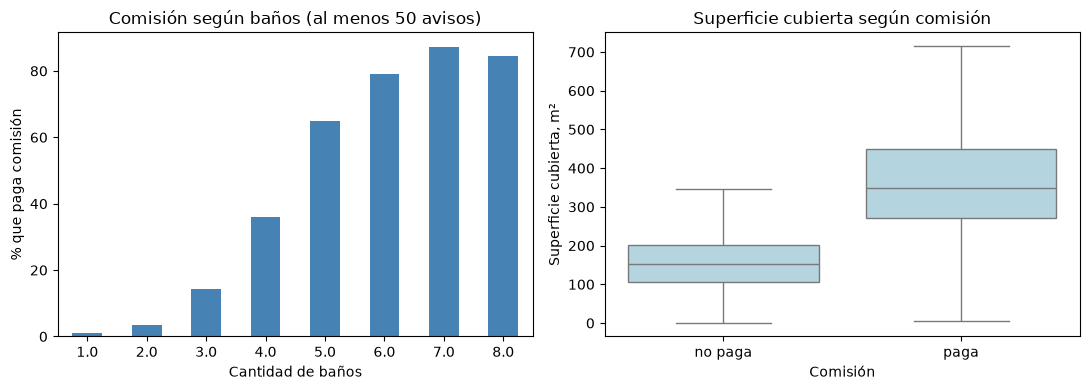

In [371]:
# Porcentaje que paga para cada cantidad de baños.
comision_banos = eda_clases.groupby('bathrooms')['paga'].mean() * 100
cantidad_banos = eda_clases.groupby('bathrooms').size()
comision_banos = comision_banos[cantidad_banos >= 50]

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

comision_banos.plot.bar(ax=ejes[0], rot=0, color='steelblue')
ejes[0].set_title('Comisión según baños (al menos 50 avisos)')
ejes[0].set_xlabel('Cantidad de baños')
ejes[0].set_ylabel('% que paga comisión')

sns.boxplot(data=eda_clases, x='paga_comision', y='surface_covered',
    order=['no paga', 'paga'], showfliers=False, color='lightblue', ax=ejes[1])
ejes[1].set_title('Superficie cubierta según comisión')
ejes[1].set_xlabel('Comisión')
ejes[1].set_ylabel('Superficie cubierta, m²')

plt.tight_layout()
plt.show()


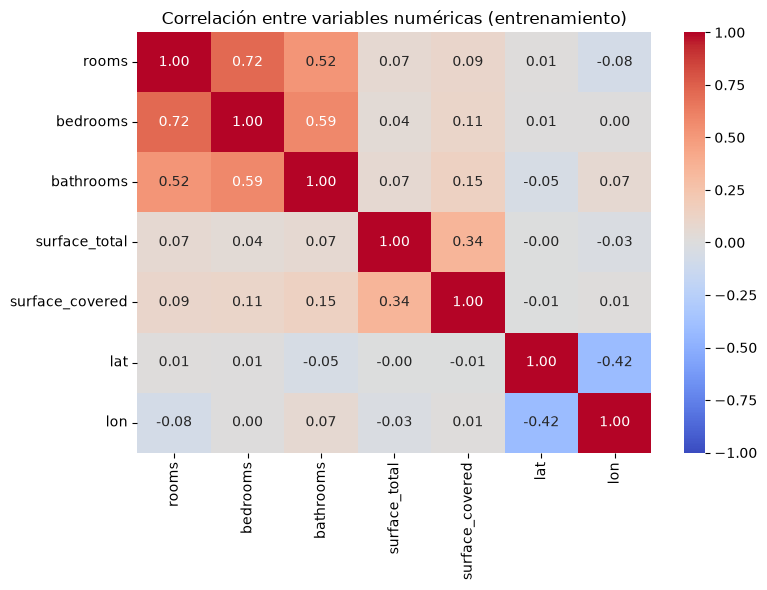

In [372]:
plt.figure(figsize=(8, 6))
sns.heatmap(eda_clases[numericas].corr(), annot=True, fmt='.2f',
    cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlación entre variables numéricas (entrenamiento)')
plt.tight_layout()
plt.show()


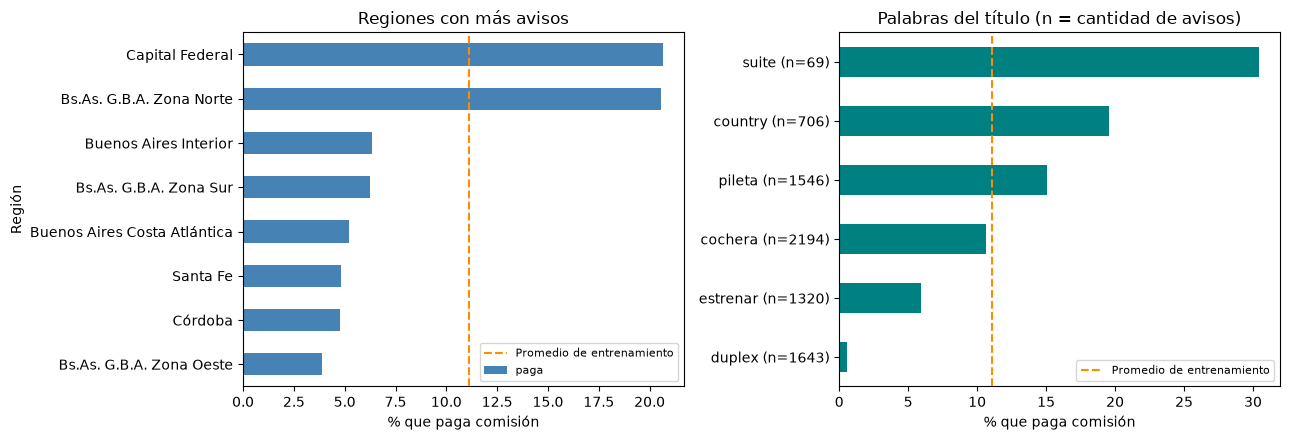

In [373]:
# Elegimos las ocho regiones con más avisos.
regiones_frecuentes = eda_clases['l2'].value_counts().head(8).index
comision_region = eda_clases.groupby('l2')['paga'].mean() * 100
comision_region = comision_region.loc[regiones_frecuentes].sort_values()

# Porcentaje que paga entre los avisos que mencionan cada palabra.
palabras_eda = ['pileta', 'country', 'suite', 'cochera', 'estrenar', 'duplex']
comision_palabras = pd.Series(index=palabras_eda, dtype=float)
etiquetas_palabras = []

for palabra in palabras_eda:
    contiene = eda_clases['titulo_' + palabra] == 1
    comision_palabras[palabra] = eda_clases.loc[contiene, 'paga'].mean() * 100
    etiquetas_palabras.append(palabra + ' (n=' + str(contiene.sum()) + ')')

comision_palabras.index = etiquetas_palabras
comision_palabras = comision_palabras.sort_values()
promedio_paga = y_train.mean() * 100

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

comision_region.plot.barh(ax=ejes[0], color='steelblue')
ejes[0].set_title('Regiones con más avisos')
ejes[0].set_xlabel('% que paga comisión')
ejes[0].set_ylabel('Región')

comision_palabras.plot.barh(ax=ejes[1], color='teal')
ejes[1].set_title('Palabras del título (n = cantidad de avisos)')
ejes[1].set_xlabel('% que paga comisión')
ejes[1].set_ylabel('')

for eje in ejes:
    eje.axvline(promedio_paga, color='darkorange', linestyle='--', label='Promedio de entrenamiento')
    eje.legend(loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()


**Observaciones**

- Las propiedades que pagan tienen medianas mayores: **4 frente a 2 baños** y **350 frente a 152 m² cubiertos**.
- Ambientes y dormitorios están relacionados: su correlación es **0,72**.
- Entre las regiones con más avisos, Capital Federal y Zona Norte rondan el 20% de “paga”, por encima del promedio de 11%.
- “Country” y “pileta” superan ese promedio; “estrenar” y “duplex” quedan por debajo. “Suite” tiene una proporción alta, pero aparece en solo 69 avisos.


## 7. Imputación y codificación

Calculamos las medianas solo con el 70% de entrenamiento y usamos las mismas
para completar los faltantes del 30% de prueba. `get_dummies` convierte país
y provincia en columnas de ceros y unos.

Preparamos las columnas completas una vez. Para la prueba básica seleccionamos
solo las columnas originales y las de país/provincia ya codificadas. Las dos
versiones usan exactamente las mismas filas y el mismo tratamiento de sus datos.


In [374]:
medianas = X_train[columnas_numericas].median().fillna(0)
X_train[columnas_numericas] = X_train[columnas_numericas].fillna(medianas)
X_test[columnas_numericas] = X_test[columnas_numericas].fillna(medianas)

X_train_preparado = pd.get_dummies(X_train, columns=categoricas, dtype=int)
X_test_preparado = pd.get_dummies(X_test, columns=categoricas, dtype=int)
X_test_preparado = X_test_preparado.reindex(columns=X_train_preparado.columns, fill_value=0)

# Quitamos los extras para obtener la primera prueba, con las columnas basicas.
columnas_basicas_preparadas = X_train_preparado.columns.drop(columnas_extra)
X_train_basico = X_train_preparado[columnas_basicas_preparadas]
X_test_basico = X_test_preparado[columnas_basicas_preparadas]
print('Columnas después de codificar: básicas', X_train_basico.shape[1], '| completas', X_train_preparado.shape[1])


Columnas después de codificar: básicas 48 | completas 75


## 8. Función de ganancia

Un verdadero positivo (TP) aporta USD 100. Un falso positivo (FP) cuesta USD 50.
Los otros casos no aportan comisión. Por lo tanto: **ganancia = 100 × TP − 50 × FP**.
La función siguiente solo cuenta estos dos casos.


In [375]:
def ganancia(y_real, y_pred):
    reales = np.asarray(y_real)
    predichas = np.asarray(y_pred)
    TP = ((reales == 1) & (predichas == 1)).sum()
    FP = ((reales == 0) & (predichas == 1)).sum()
    return int(100 * TP - 50 * FP)

## 9. Pruebas de modelos por familia

Cada familia tiene sus propias pruebas, tabla y gráfico. Comparamos las columnas
**básicas y completas**, con las mismas filas **70% / 30%** y el corte de **1/3**.
En KNN y Naive Bayes, `make_pipeline` aplica el escalado aprendido con entrenamiento.
Al final comparamos el mejor resultado de cada familia.


In [376]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay


### Corte calculado con la ganancia esperada

Si `p` es la probabilidad de que una propiedad pague comisión, seleccionarla
aporta 100 con probabilidad `p` y cuesta 50 con probabilidad `1 - p`.

$$
G(p) = 100p - 50(1-p) = 150p - 50
$$

Buscamos el punto donde esa ganancia esperada es cero:

$$
150p - 50 = 0 \quad\Rightarrow\quad p = \frac{50}{150} = \frac{1}{3}
$$

Por eso fijamos **corte = 1/3**, aproximadamente **0,33**. Predecimos “paga”
cuando la probabilidad estimada alcanza ese valor. Usamos la fracción exacta
en el código, sin redondearla y sin buscar otros cortes en los datos de prueba.


In [377]:
corte_elegido = 50 / 150


### 9.1. KNN

Probamos **5, 15 y 31 vecinos**, con columnas básicas y completas. El escalado se ajusta solo con entrenamiento.


In [378]:
modelos_knn_basicos = {
    'KNN k=5': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5, n_jobs=4)),
    'KNN k=15': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15, n_jobs=4)),
    'KNN k=31': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=31, n_jobs=4)),
}

modelos_knn_completos = {
    'KNN k=5': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5, n_jobs=4)),
    'KNN k=15': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15, n_jobs=4)),
    'KNN k=31': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=31, n_jobs=4)),
}

resultados_knn = []

# Primero usamos las columnas básicas.
for nombre, modelo in modelos_knn_basicos.items():
    modelo.fit(X_train_basico, y_train)
    probabilidades = modelo.predict_proba(X_test_basico)[:, 1]
    predicciones = (probabilidades >= corte_elegido).astype(int)
    resultados_knn.append([nombre, 'Básicas', corte_elegido,
        ganancia(y_test, predicciones), accuracy_score(y_test, predicciones)])

# Después repetimos con las columnas completas.
for nombre, modelo in modelos_knn_completos.items():
    modelo.fit(X_train_preparado, y_train)
    probabilidades = modelo.predict_proba(X_test_preparado)[:, 1]
    predicciones = (probabilidades >= corte_elegido).astype(int)
    resultados_knn.append([nombre, 'Completas', corte_elegido,
        ganancia(y_test, predicciones), accuracy_score(y_test, predicciones)])

tabla_knn = pd.DataFrame(resultados_knn,
    columns=['modelo', 'variables', 'corte', 'ganancia_test', 'accuracy'])


,modelo,variables,corte,ganancia_test,accuracy
0,KNN k=5,Básicas,0.333333,94150,0.912580
1,KNN k=15,Básicas,0.333333,96250,0.917019
2,KNN k=31,Básicas,0.333333,93300,0.918697
3,KNN k=5,Completas,0.333333,91900,0.913825
4,KNN k=15,Completas,0.333333,89200,0.916910
5,KNN k=31,Completas,0.333333,83100,0.919887


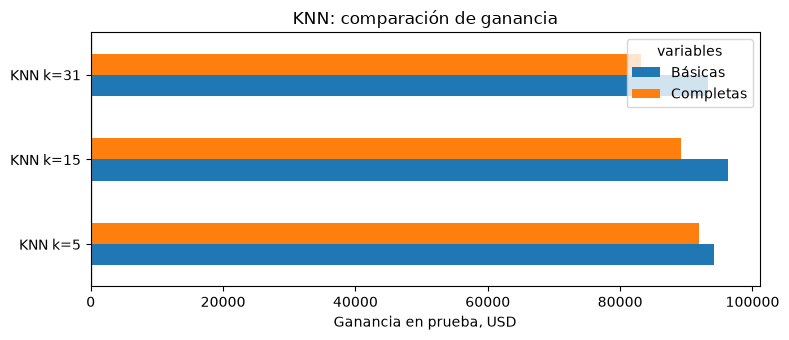

Mejor resultado: KNN k=15 | Básicas | Ganancia: 96250


In [379]:
display(tabla_knn)

ganancias_knn = tabla_knn.pivot(index='modelo', columns='variables', values='ganancia_test')
ganancias_knn = ganancias_knn.reindex(list(modelos_knn_basicos))
ganancias_knn.plot.barh(figsize=(8, 3.5))
plt.axvline(0, color='grey', linewidth=1)
plt.title('KNN: comparación de ganancia')
plt.xlabel('Ganancia en prueba, USD')
plt.ylabel('')
plt.tight_layout()
plt.show()

mejor_knn = tabla_knn.sort_values('ganancia_test', ascending=False, kind='stable').iloc[0].copy()
mejor_knn['familia'] = 'KNN'
print('Mejor resultado:', mejor_knn['modelo'], '|', mejor_knn['variables'],
      '| Ganancia:', mejor_knn['ganancia_test'])


### 9.2. Naive Bayes

Probamos **GaussianNB con sus parámetros por defecto**, usando columnas básicas y completas.


In [380]:
modelos_nb_basicos = {
    'Naive Bayes': make_pipeline(StandardScaler(), GaussianNB()),
}

modelos_nb_completos = {
    'Naive Bayes': make_pipeline(StandardScaler(), GaussianNB()),
}

resultados_nb = []

# Primero usamos las columnas básicas.
for nombre, modelo in modelos_nb_basicos.items():
    modelo.fit(X_train_basico, y_train)
    probabilidades = modelo.predict_proba(X_test_basico)[:, 1]
    predicciones = (probabilidades >= corte_elegido).astype(int)
    resultados_nb.append([nombre, 'Básicas', corte_elegido,
        ganancia(y_test, predicciones), accuracy_score(y_test, predicciones)])

# Después repetimos con las columnas completas.
for nombre, modelo in modelos_nb_completos.items():
    modelo.fit(X_train_preparado, y_train)
    probabilidades = modelo.predict_proba(X_test_preparado)[:, 1]
    predicciones = (probabilidades >= corte_elegido).astype(int)
    resultados_nb.append([nombre, 'Completas', corte_elegido,
        ganancia(y_test, predicciones), accuracy_score(y_test, predicciones)])

tabla_nb = pd.DataFrame(resultados_nb,
    columns=['modelo', 'variables', 'corte', 'ganancia_test', 'accuracy'])


,modelo,variables,corte,ganancia_test,accuracy
0,Naive Bayes,Básicas,0.333333,-598300,0.131157
1,Naive Bayes,Completas,0.333333,-563750,0.168832


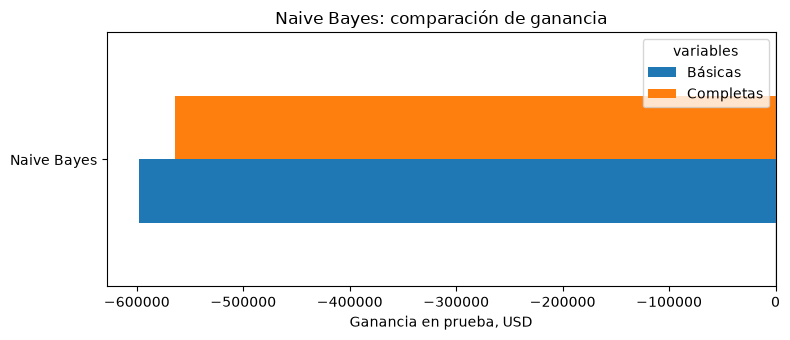

Mejor resultado: Naive Bayes | Completas | Ganancia: -563750


In [381]:
display(tabla_nb)

ganancias_nb = tabla_nb.pivot(index='modelo', columns='variables', values='ganancia_test')
ganancias_nb = ganancias_nb.reindex(list(modelos_nb_basicos))
ganancias_nb.plot.barh(figsize=(8, 3.5))
plt.axvline(0, color='grey', linewidth=1)
plt.title('Naive Bayes: comparación de ganancia')
plt.xlabel('Ganancia en prueba, USD')
plt.ylabel('')
plt.tight_layout()
plt.show()

mejor_nb = tabla_nb.sort_values('ganancia_test', ascending=False, kind='stable').iloc[0].copy()
mejor_nb['familia'] = 'Naive Bayes'
print('Mejor resultado:', mejor_nb['modelo'], '|', mejor_nb['variables'],
      '| Ganancia:', mejor_nb['ganancia_test'])


### 9.3. Árboles de decisión

Probamos profundidades **3, 6, 12 y 20**, con un mínimo de **10 avisos por hoja**. También comparamos profundidad 6 con mínimo de 20.


In [382]:
modelos_arbol_basicos = {
    'Árbol prof. 6': DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=42),
    'Árbol prof. 3': DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=42),
    'Árbol prof. 12': DecisionTreeClassifier(max_depth=12, min_samples_leaf=10, random_state=42),
    'Árbol prof. 20': DecisionTreeClassifier(max_depth=20, min_samples_leaf=10, random_state=42),
    'Árbol prof. 6, hoja 20': DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=42),
}

modelos_arbol_completos = {
    'Árbol prof. 6': DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=42),
    'Árbol prof. 3': DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=42),
    'Árbol prof. 12': DecisionTreeClassifier(max_depth=12, min_samples_leaf=10, random_state=42),
    'Árbol prof. 20': DecisionTreeClassifier(max_depth=20, min_samples_leaf=10, random_state=42),
    'Árbol prof. 6, hoja 20': DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=42),
}

resultados_arbol = []

# Primero usamos las columnas básicas.
for nombre, modelo in modelos_arbol_basicos.items():
    modelo.fit(X_train_basico, y_train)
    probabilidades = modelo.predict_proba(X_test_basico)[:, 1]
    predicciones = (probabilidades >= corte_elegido).astype(int)
    resultados_arbol.append([nombre, 'Básicas', corte_elegido,
        ganancia(y_test, predicciones), accuracy_score(y_test, predicciones)])

# Después repetimos con las columnas completas.
for nombre, modelo in modelos_arbol_completos.items():
    modelo.fit(X_train_preparado, y_train)
    probabilidades = modelo.predict_proba(X_test_preparado)[:, 1]
    predicciones = (probabilidades >= corte_elegido).astype(int)
    resultados_arbol.append([nombre, 'Completas', corte_elegido,
        ganancia(y_test, predicciones), accuracy_score(y_test, predicciones)])

tabla_arbol = pd.DataFrame(resultados_arbol,
    columns=['modelo', 'variables', 'corte', 'ganancia_test', 'accuracy'])


,modelo,variables,corte,ganancia_test,accuracy
0,Árbol prof. 6,Básicas,0.333333,98200,0.926924
1,Árbol prof. 3,Básicas,0.333333,90650,0.918264
2,Árbol prof. 12,Básicas,0.333333,101200,0.921998
3,Árbol prof. 20,Básicas,0.333333,99400,0.917830
4,"Árbol prof. 6, hoja 20",Básicas,0.333333,97300,0.926329
5,Árbol prof. 6,Completas,0.333333,109050,0.928223
6,Árbol prof. 3,Completas,0.333333,88650,0.911335
7,Árbol prof. 12,Completas,0.333333,118550,0.933961
8,Árbol prof. 20,Completas,0.333333,118050,0.931038
9,"Árbol prof. 6, hoja 20",Completas,0.333333,109000,0.928223


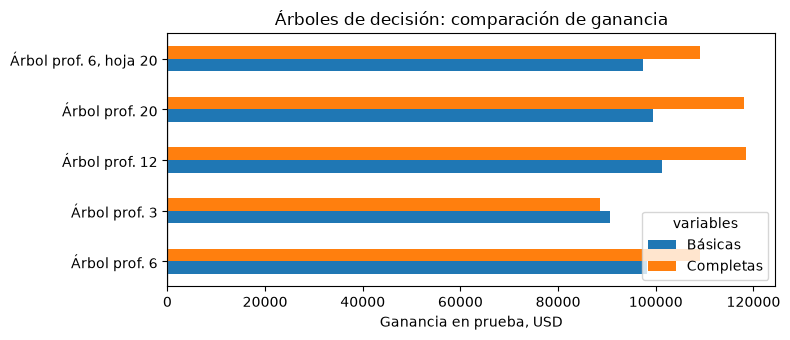

Mejor resultado: Árbol prof. 12 | Completas | Ganancia: 118550


In [383]:
display(tabla_arbol)

ganancias_arbol = tabla_arbol.pivot(index='modelo', columns='variables', values='ganancia_test')
ganancias_arbol = ganancias_arbol.reindex(list(modelos_arbol_basicos))
ganancias_arbol.plot.barh(figsize=(8, 3.5))
plt.axvline(0, color='grey', linewidth=1)
plt.title('Árboles de decisión: comparación de ganancia')
plt.xlabel('Ganancia en prueba, USD')
plt.ylabel('')
plt.tight_layout()
plt.show()

mejor_arbol = tabla_arbol.sort_values('ganancia_test', ascending=False, kind='stable').iloc[0].copy()
mejor_arbol['familia'] = 'Árbol'
print('Mejor resultado:', mejor_arbol['modelo'], '|', mejor_arbol['variables'],
      '| Ganancia:', mejor_arbol['ganancia_test'])


### 9.4. Random Forest

Probamos profundidades **8, 12, 16 y 20** con 200 árboles y mínimo de 1 aviso por hoja. También contrastamos 100 árboles en profundidad 20 y mínimo de 2 avisos por hoja en profundidad 16. En todos usamos `max_features=0.5` y `random_state=42`.


In [384]:
modelos_rf_basicos = {
    'RF prof. 8': RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=1, max_features=0.5, random_state=42, n_jobs=4),
    'RF prof. 12': RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=1, max_features=0.5, random_state=42, n_jobs=4),
    'RF prof. 16': RandomForestClassifier(n_estimators=200, max_depth=16, min_samples_leaf=1, max_features=0.5, random_state=42, n_jobs=4),
    'RF prof. 20': RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_leaf=1, max_features=0.5, random_state=42, n_jobs=4),
    'RF prof. 16, hoja 2': RandomForestClassifier(n_estimators=200, max_depth=16, min_samples_leaf=2, max_features=0.5, random_state=42, n_jobs=4),
    'RF prof. 20, 100 árboles': RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=1, max_features=0.5, random_state=42, n_jobs=4),
}

modelos_rf_completos = {
    'RF prof. 8': RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=1, max_features=0.5, random_state=42, n_jobs=4),
    'RF prof. 12': RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=1, max_features=0.5, random_state=42, n_jobs=4),
    'RF prof. 16': RandomForestClassifier(n_estimators=200, max_depth=16, min_samples_leaf=1, max_features=0.5, random_state=42, n_jobs=4),
    'RF prof. 20': RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_leaf=1, max_features=0.5, random_state=42, n_jobs=4),
    'RF prof. 16, hoja 2': RandomForestClassifier(n_estimators=200, max_depth=16, min_samples_leaf=2, max_features=0.5, random_state=42, n_jobs=4),
    'RF prof. 20, 100 árboles': RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=1, max_features=0.5, random_state=42, n_jobs=4),
}

resultados_rf = []

# Primero usamos las columnas básicas.
for nombre, modelo in modelos_rf_basicos.items():
    modelo.fit(X_train_basico, y_train)
    probabilidades = modelo.predict_proba(X_test_basico)[:, 1]
    predicciones = (probabilidades >= corte_elegido).astype(int)
    resultados_rf.append([nombre, 'Básicas', corte_elegido,
        ganancia(y_test, predicciones), accuracy_score(y_test, predicciones)])

# Después repetimos con las columnas completas.
for nombre, modelo in modelos_rf_completos.items():
    modelo.fit(X_train_preparado, y_train)
    probabilidades = modelo.predict_proba(X_test_preparado)[:, 1]
    predicciones = (probabilidades >= corte_elegido).astype(int)
    resultados_rf.append([nombre, 'Completas', corte_elegido,
        ganancia(y_test, predicciones), accuracy_score(y_test, predicciones)])

tabla_rf = pd.DataFrame(resultados_rf,
    columns=['modelo', 'variables', 'corte', 'ganancia_test', 'accuracy'])


,modelo,variables,corte,ganancia_test,accuracy
0,RF prof. 8,Básicas,0.333333,107450,0.931092
1,RF prof. 12,Básicas,0.333333,118100,0.936072
2,RF prof. 16,Básicas,0.333333,120550,0.937588
3,RF prof. 20,Básicas,0.333333,121100,0.936830
4,"RF prof. 16, hoja 2",Básicas,0.333333,119500,0.936343
5,"RF prof. 20, 100 árboles",Básicas,0.333333,121050,0.936776
6,RF prof. 8,Completas,0.333333,120450,0.938941
7,RF prof. 12,Completas,0.333333,129750,0.944625
8,RF prof. 16,Completas,0.333333,134900,0.946628
9,RF prof. 20,Completas,0.333333,137100,0.948252


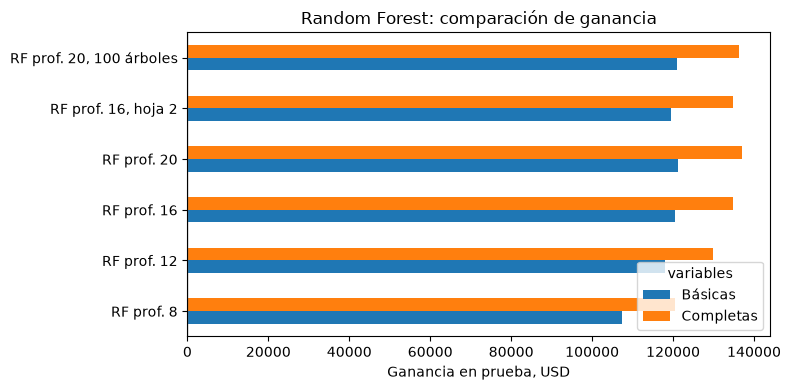

Mejor resultado: RF prof. 20 | Completas | Ganancia: 137100


In [385]:
display(tabla_rf)

ganancias_rf = tabla_rf.pivot(index='modelo', columns='variables', values='ganancia_test')
ganancias_rf = ganancias_rf.reindex(list(modelos_rf_basicos))
ganancias_rf.plot.barh(figsize=(8, 4))
plt.axvline(0, color='grey', linewidth=1)
plt.title('Random Forest: comparación de ganancia')
plt.xlabel('Ganancia en prueba, USD')
plt.ylabel('')
plt.tight_layout()
plt.show()

mejor_rf = tabla_rf.sort_values('ganancia_test', ascending=False, kind='stable').iloc[0].copy()
mejor_rf['familia'] = 'Random Forest'
print('Mejor resultado:', mejor_rf['modelo'], '|', mejor_rf['variables'],
      '| Ganancia:', mejor_rf['ganancia_test'])


### 9.5. Comparación final

Reunimos el mejor resultado de cada familia y elegimos la mayor ganancia.
Como usamos este 30% para comparar y elegir, la ganancia es un resultado de comparación.


In [386]:
finalistas = pd.DataFrame([mejor_knn, mejor_nb, mejor_arbol, mejor_rf])
finalistas = finalistas.sort_values('ganancia_test', ascending=False, kind='stable').reset_index(drop=True)
display(finalistas[['familia', 'modelo', 'variables', 'ganancia_test', 'accuracy']])

# Reunimos los modelos que ya entrenamos en cada sección.
modelos_basicos = {}
modelos_basicos.update(modelos_knn_basicos)
modelos_basicos.update(modelos_nb_basicos)
modelos_basicos.update(modelos_arbol_basicos)
modelos_basicos.update(modelos_rf_basicos)

modelos_completos = {}
modelos_completos.update(modelos_knn_completos)
modelos_completos.update(modelos_nb_completos)
modelos_completos.update(modelos_arbol_completos)
modelos_completos.update(modelos_rf_completos)

comparacion = pd.concat([tabla_knn, tabla_nb, tabla_arbol, tabla_rf], ignore_index=True)
mejor = finalistas.iloc[0]
nombre_modelo_elegido = mejor['modelo']
variables_elegidas = mejor['variables']

if variables_elegidas == 'Básicas':
    columnas_elegidas = columnas_basicas
    modelo_elegido = modelos_basicos[nombre_modelo_elegido]
    X_train_elegido = X_train_basico
    X_test_elegido = X_test_basico
else:
    columnas_elegidas = columnas_completas
    modelo_elegido = modelos_completos[nombre_modelo_elegido]
    X_train_elegido = X_train_preparado
    X_test_elegido = X_test_preparado

print('Elegimos:', nombre_modelo_elegido, '|', variables_elegidas,
      '| Ganancia:', mejor['ganancia_test'])


,familia,modelo,variables,ganancia_test,accuracy
0,Random Forest,RF prof. 20,Completas,137100,0.948252
1,Árbol,Árbol prof. 12,Completas,118550,0.933961
2,KNN,KNN k=15,Básicas,96250,0.917019
3,Naive Bayes,Naive Bayes,Completas,-563750,0.168832


Elegimos: RF prof. 20 | Completas | Ganancia: 137100


## 10. Evaluación del modelo elegido

Mostramos su ganancia, matriz de confusión y curva ROC en las mismas filas de prueba.
El corte sigue siendo **1/3**.


In [387]:
probabilidades_test = modelo_elegido.predict_proba(X_test_elegido)[:, 1]
predicciones_test = (probabilidades_test >= corte_elegido).astype(int)


GANANCIA EN TEST: US$ 137100
              precision    recall  f1-score   support

     no paga       0.98      0.97      0.97     16423
        paga       0.75      0.80      0.78      2051

    accuracy                           0.95     18474
   macro avg       0.86      0.88      0.87     18474
weighted avg       0.95      0.95      0.95     18474



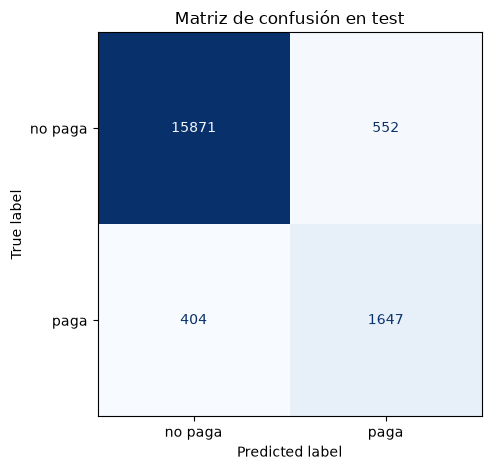

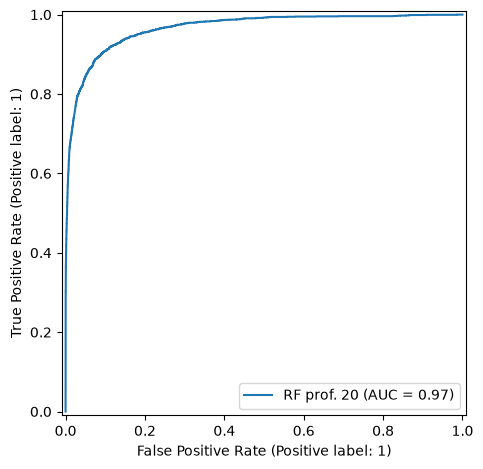

In [388]:
ganancia_test = ganancia(y_test, predicciones_test)
print('GANANCIA EN TEST: US$', ganancia_test)
print(classification_report(y_test, predicciones_test, target_names=['no paga', 'paga']))

ConfusionMatrixDisplay.from_predictions(y_test, predicciones_test,
    display_labels=['no paga', 'paga'], cmap='Blues', colorbar=False)
plt.title('Matriz de confusión en test')
plt.tight_layout()
plt.show()
RocCurveDisplay.from_predictions(y_test, probabilidades_test, name=nombre_modelo_elegido)
plt.tight_layout()
plt.show()


### Variables importantes

Si ganó un árbol o Random Forest, mostramos qué variables usó más en sus divisiones.
Esta importancia no demuestra causalidad.


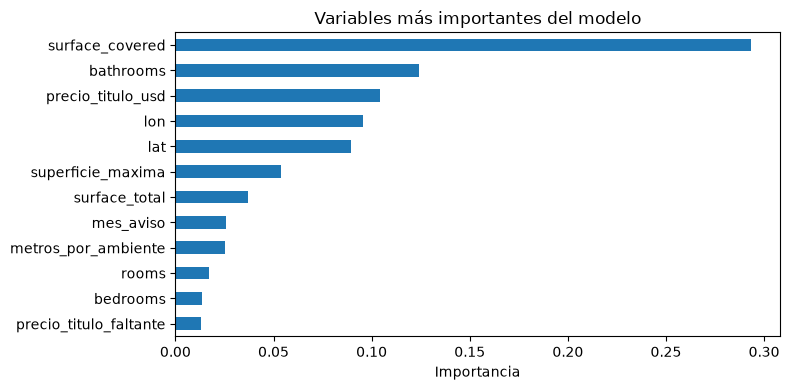

In [389]:
# Esta medida de importancia corresponde a los modelos de árboles.
if isinstance(modelo_elegido, (DecisionTreeClassifier, RandomForestClassifier)):
    importancias = pd.Series(modelo_elegido.feature_importances_, index=X_train_elegido.columns)
    importancias.nlargest(12).sort_values().plot.barh(figsize=(8, 4))
    plt.title('Variables más importantes del modelo')
    plt.xlabel('Importancia')
    plt.tight_layout()
    plt.show()
else:
    print('El modelo elegido no es de árboles: no tiene esta medida de importancia.')


## 11. Entrenamiento final y entrega

Entrenamos el modelo elegido con todos los datos etiquetados y recalculamos
su preparación con esos datos. Conservamos las columnas y el corte de **1/3**.
El CSV contiene los IDs predichos como “paga”.


In [390]:
X_final = X[columnas_elegidas].copy()
X_predict_final = X_predict[columnas_elegidas].copy()
medianas_finales = X_final.median(numeric_only=True).fillna(0)
X_final = X_final.fillna(medianas_finales)
X_predict_final = X_predict_final.fillna(medianas_finales)
X_final = pd.get_dummies(X_final, columns=categoricas, dtype=int)
X_predict_final = pd.get_dummies(X_predict_final, columns=categoricas, dtype=int)
X_predict_final = X_predict_final.reindex(columns=X_final.columns, fill_value=0)

modelo_elegido.fit(X_final, y)
probabilidades_finales = modelo_elegido.predict_proba(X_predict_final)[:, 1]


In [391]:
ids_paga = X_predict.index[probabilidades_finales >= corte_elegido]
entrega = pd.DataFrame({'id': ids_paga})
assert entrega['id'].is_unique
assert entrega['id'].isin(df_predict.index).all()
assert not entrega['id'].isin(df_train.index).any()
entrega.to_csv('casas_entrega.csv', index=False)
print('IDs incluidos en la entrega:', len(entrega))
display(entrega.head())

try:
    from google.colab import files
except ImportError:
    print('Archivo guardado: casas_entrega.csv')
else:
    files.download('casas_entrega.csv')

IDs incluidos en la entrega: 4835


,id
0,lhXkg2in7fvNqT4kYwu7eQ==
1,FnpmEp/Q5TPcY7tXJpSOZA==
2,idfOLFITsmAsXvnlE409Wg==
3,rGeUOykJC6l5eLEt+0lvWA==
4,hx+zvTEout7mE0Qo3sAJzw==


Archivo guardado: casas_entrega.csv


## 12. Modelo alternativo sin 850 filas repetidas

 Los conjuntos con clasescontradictorias siguen presentes. Repetimos la separación 70% / 30%
y preparamos los datos usando solo el nuevo entrenamiento.

Para comparar, mantenemos el tipo de modelo, sus parámetros, las variables y
el corte elegidos antes. **Las filas de prueba cambian**, por lo que la diferencia
de ganancia muestra el resultado de esta corrida, no aísla el efecto de quitar
filas. La entrega del punto 11 sigue usando todos los datos originales.



In [392]:
from sklearn.base import clone

columnas_para_duplicados = [c for c in df_train.columns if c != 'paga_comision']

# Para cada fila, contamos cuántas clases hay entre las filas con los mismos datos.
clases_distintas_por_fila = df_train.groupby(
    columnas_para_duplicados, dropna=False
)['paga_comision'].transform('nunique')


# La primera aparición se conserva. Estas son la segunda y las siguientes.
es_copia = df_train.duplicated(subset=columnas_para_duplicados, keep='first')

# Solo quitamos copias si todas las filas del conjunto tienen la misma clase.
sin_conflicto_de_clase = clases_distintas_por_fila.eq(1)
ids_a_quitar = df_train.index[es_copia & sin_conflicto_de_clase]

df_train_modelo = df_train.drop(index=ids_a_quitar)
datos_train_modelo = datos_train.drop(index=ids_a_quitar)
print('Filas quitadas:', len(ids_a_quitar))

X_sin_duplicados = datos_train_modelo[columnas_elegidas].copy()
y_sin_duplicados = df_train_modelo['paga_comision'].map({'no paga': 0, 'paga': 1})

X_train_sin, X_test_sin, y_train_sin, y_test_sin = train_test_split(
    X_sin_duplicados,
    y_sin_duplicados,
    test_size=0.30,
    random_state=42,
    stratify=y_sin_duplicados
)

# Ajustamos medianas y codificación con este entrenamiento, sin usar su prueba.
columnas_numericas_sin = [c for c in columnas_numericas if c in X_train_sin.columns]
medianas_sin = X_train_sin[columnas_numericas_sin].median().fillna(0)
X_train_sin[columnas_numericas_sin] = X_train_sin[columnas_numericas_sin].fillna(medianas_sin)
X_test_sin[columnas_numericas_sin] = X_test_sin[columnas_numericas_sin].fillna(medianas_sin)

X_train_sin = pd.get_dummies(X_train_sin, columns=categoricas, dtype=int)
X_test_sin = pd.get_dummies(X_test_sin, columns=categoricas, dtype=int)
X_test_sin = X_test_sin.reindex(columns=X_train_sin.columns, fill_value=0)

print('Modelo:', nombre_modelo_elegido, '| Variables:', variables_elegidas)
print('Filas entrenamiento:', len(X_train_sin), '| Filas prueba:', len(X_test_sin))


Filas quitadas: 850
Modelo: RF prof. 20 | Variables: Completas
Filas entrenamiento: 42508 | Filas prueba: 18219


,entrenamiento,filas prueba,ganancia (USD),ganancia por 1000 filas (USD)
0,Todas las filas,18474,137100,7421.2
1,Sin 850 repetidas,18219,136100,7470.2


              precision    recall  f1-score   support

     no paga       0.97      0.97      0.97     16189
        paga       0.77      0.79      0.78      2030

    accuracy                           0.95     18219
   macro avg       0.87      0.88      0.88     18219
weighted avg       0.95      0.95      0.95     18219



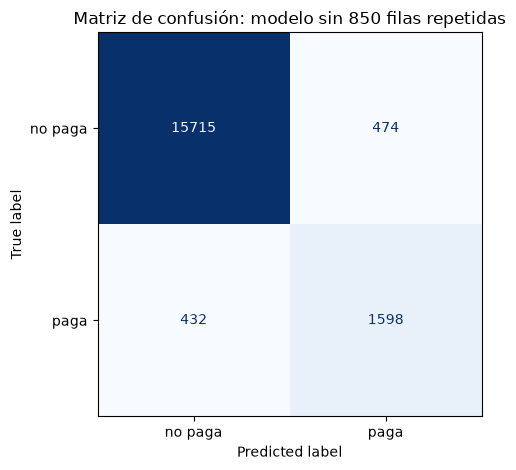

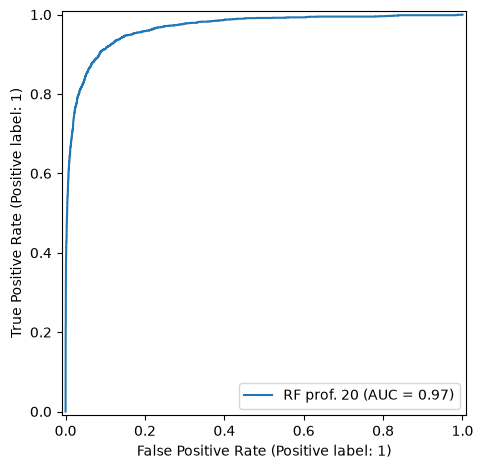

In [393]:
modelo_sin_duplicados = clone(modelo_elegido)
modelo_sin_duplicados.fit(X_train_sin, y_train_sin)
probabilidades_sin = modelo_sin_duplicados.predict_proba(X_test_sin)[:, 1]
predicciones_sin = (probabilidades_sin >= corte_elegido).astype(int)
ganancia_sin = ganancia(y_test_sin, predicciones_sin)

comparacion_duplicados = pd.DataFrame({
    'entrenamiento': ['Todas las filas', 'Sin 850 repetidas'],
    'filas prueba': [len(y_test), len(y_test_sin)],
    'ganancia (USD)': [ganancia_test, ganancia_sin],
    'ganancia por 1000 filas (USD)': [
        1000 * ganancia_test / len(y_test),
        1000 * ganancia_sin / len(y_test_sin)
    ]
})
display(comparacion_duplicados.round(1))
print(classification_report(y_test_sin, predicciones_sin,
                            target_names=['no paga', 'paga']))
ConfusionMatrixDisplay.from_predictions(
    y_test_sin, predicciones_sin,
    display_labels=['no paga', 'paga'], cmap='Blues', colorbar=False
)
plt.title('Matriz de confusión: modelo sin 850 filas repetidas')
plt.tight_layout()
plt.show()
RocCurveDisplay.from_predictions(
    y_test_sin, probabilidades_sin, name=nombre_modelo_elegido
)
plt.tight_layout()
plt.show()


## 13. Conclusión

Comparamos KNN, Naive Bayes, árboles y Random Forest por separado, con columnas
básicas y completas. La tabla final resume el mejor resultado de cada familia.

Elegimos por ganancia con el corte de **1/3**. La ganancia observada corresponde
a esta comparación; la entrega usa el modelo elegido entrenado con todos los datos etiquetados.

El punto 12 repite el entrenamiento sin 850 filas adicionales y muestra sus
resultados con una nueva separación. Como cambia la prueba, las ganancias
no son una comparación causal del efecto de quitar esas filas.


In [394]:
print('Modelo elegido:', nombre_modelo_elegido)
print('Variables:', variables_elegidas, '| Corte:', corte_elegido)
print('Ganancia en prueba:', ganancia_test)
print('Entrega: casas_entrega_titulos.csv')


Modelo elegido: RF prof. 20
Variables: Completas | Corte: 0.3333333333333333
Ganancia en prueba: 137100
Entrega: casas_entrega_titulos.csv
